# New EDA — old + new features

Statistics report over the **combined** feature set:

* **old** = all 77 source columns from `Data Science Task Data.xlsx - Result 1.csv`
* **new** = the 42 derived columns from `features/player_features.csv`
* combined: **119 columns × 100,000 rows** (aligned on `player_id`)

Every column is summarised with exactly this structure (metrics as rows):

```
missing %   zero %   negative %   unique %
mean   median   std   min
P01   P05   P25   P50   P75   P95   P99   max   skewness
```

**Metric definitions**

| metric | definition |
|---|---|
| `missing %` | `NaN / 100,000 × 100` (denominator = all rows) |
| `zero %` | exact `0` values / 100,000 × 100 (numeric/bool/datetime only) |
| `negative %` | values `< 0` / 100,000 × 100 (numeric/bool/datetime only) |
| `unique %` | `nunique(dropna=True) / 100,000 × 100` |
| `mean median std min P01…P99 max skewness` | over **non-missing** values; percentiles linear-interpolated; `std` ddof=1; `skewness` = pandas sample skew |

**Column-class handling**

* **numeric** — full 17-row grid.
* **bool / bool-like text** (`True/False` values in an object column) — treated as 1/0: `mean` = share True, `zero %` = share False.
* **datetime** — computed in **epoch-days since 1970-01-01** so min/percentiles/max show the time range (e.g. `20,681` ≈ 2026-04).
* **text** — only `missing %` and `unique %` are defined; the remaining rows are `NaN` (displayed tables drop rows that are entirely `NaN` for that block; the saved CSVs keep all 17 rows).

**Outputs → `new_eda_output/`**
`stats_all.csv` (17 × 119), `stats_old.csv`, `stats_new.csv`, `column_inventory.csv`,
`new_eda_report.txt`, `missingness.png`, `new_feature_distributions.png`,
`new_feature_correlations.png`, `categorical_counts.png`

In [1]:
%matplotlib inline

import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="talk")

SRC = "Data Science Task Data.xlsx - Result 1.csv"
FEATS = "features/player_features.csv"
DICT = "features/feature_dictionary.csv"
OUT = "new_eda_output"
os.makedirs(OUT, exist_ok=True)

old = pd.read_csv(SRC, low_memory=False)
OLD_DATES = ["registration_date", "modified_at", "closed_at", "tc_accepted_date",
             "birth_date", "marketing_click_date", "loaded_at",
             "vip_status_updated_at", "first_deposit_day"]
for c in OLD_DATES:
    old[c] = pd.to_datetime(old[c], errors="coerce")

newf = pd.read_csv(FEATS, low_memory=False)
for c in ["registration_date", "first_deposit_day", "closed_at"]:
    newf[c] = pd.to_datetime(newf[c], errors="coerce")

derived = [c for c in newf.columns if c not in old.columns]
assert len(derived) == 42, f"expected 42 derived cols, got {len(derived)}"

combined = old.copy()
for c in derived:
    combined[c] = newf[c]

origin = pd.concat([pd.Series("old", index=old.columns, dtype="object"),
                    pd.Series("new", index=derived, dtype="object")])

print(f"combined        : {combined.shape[0]} rows x {combined.shape[1]} cols")
print(f"old features    : {len(old.columns)}")
print(f"new features    : {len(derived)}")
print(f"date columns    : {len(OLD_DATES)} parsed in old source")

combined        : 100000 rows x 119 cols
old features    : 77
new features    : 42
date columns    : 9 parsed in old source


In [2]:
METRICS = ["missing %", "zero %", "negative %", "unique %",
           "mean", "median", "std", "min",
           "P01", "P05", "P25", "P50", "P75", "P95", "P99", "max", "skewness"]
NUMERIC_METRICS = METRICS[4:]


def to_num(s):
    # datetime -> epoch days, bool/flag -> 1/0, numeric -> float, else None
    if pd.api.types.is_datetime64_any_dtype(s):
        return (s - pd.Timestamp("1970-01-01")).dt.total_seconds() / 86400
    if pd.api.types.is_bool_dtype(s):
        return s.astype("float64")
    if pd.api.types.is_numeric_dtype(s):
        return s.astype("float64")
    vals = set(map(str, s.dropna().unique()))
    if vals and vals <= {"True", "False", "true", "false"}:
        mapped = s.astype("string").map(
            {"True": 1.0, "False": 0.0, "true": 1.0, "false": 0.0})
        return pd.to_numeric(mapped, errors="coerce")
    return None


def classify(s):
    if pd.api.types.is_datetime64_any_dtype(s):
        return "datetime"
    if pd.api.types.is_bool_dtype(s):
        return "bool"
    if pd.api.types.is_numeric_dtype(s):
        return "numeric"
    if to_num(s) is not None:
        return "bool"
    return "text"


def summarize(df, cols):
    n = len(df)
    out = {}
    for c in cols:
        s = df[c]
        d = {"missing %": s.isna().mean() * 100,
             "zero %": np.nan, "negative %": np.nan,
             "unique %": s.nunique(dropna=True) / n * 100}
        x = to_num(s)
        if x is not None:
            xv = x.dropna()
            d["zero %"] = float((xv == 0).sum()) / n * 100
            d["negative %"] = float((xv < 0).sum()) / n * 100
            if len(xv):
                q = xv.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
                d.update({"mean": xv.mean(), "median": xv.median(),
                          "std": xv.std(ddof=1), "min": xv.min(),
                          "P01": q.loc[0.01], "P05": q.loc[0.05],
                          "P25": q.loc[0.25], "P50": q.loc[0.5],
                          "P75": q.loc[0.75], "P95": q.loc[0.95],
                          "P99": q.loc[0.99], "max": xv.max(),
                          "skewness": xv.skew()})
        for m in METRICS:
            d.setdefault(m, np.nan)
        out[c] = d
    return pd.DataFrame(out, index=METRICS)


def show(title, block, sections=None):
    print(title)
    trimmed = block.dropna(how="all")
    display(trimmed.round(4))
    if sections is not None:
        sections.append((title, block))


print("helpers ready:", METRICS)

helpers ready: ['missing %', 'zero %', 'negative %', 'unique %', 'mean', 'median', 'std', 'min', 'P01', 'P05', 'P25', 'P50', 'P75', 'P95', 'P99', 'max', 'skewness']


In [3]:
fdict = pd.read_csv(DICT)
in_structure = set(fdict["feature"])

inv = pd.DataFrame({
    "feature": list(combined.columns),
    "origin": [origin[c] for c in combined.columns],
    "dtype_class": [classify(combined[c]) for c in combined.columns],
    "dtype": [str(combined[c].dtype) for c in combined.columns],
    "n_unique": [combined[c].nunique(dropna=True) for c in combined.columns],
    "missing_n": [int(combined[c].isna().sum()) for c in combined.columns],
    "in_12group_structure": [c in in_structure for c in combined.columns],
})

print("origin x dtype_class:")
display(pd.crosstab(inv["origin"], inv["dtype_class"]))
print("old source columns NOT carried into the 12-group structure:",
      int(((inv.origin == "old") & ~inv.in_12group_structure).sum()))
print("key column:", inv.loc[inv.feature == "player_id"].to_dict("records"))
display(inv.head(8))

origin x dtype_class:


dtype_class,bool,datetime,numeric,text
origin,,,,
new,13,0,26,3
old,8,9,20,40


old source columns NOT carried into the 12-group structure: 27
key column: [{'feature': 'player_id', 'origin': 'old', 'dtype_class': 'numeric', 'dtype': 'int64', 'n_unique': 100000, 'missing_n': 0, 'in_12group_structure': True}]


,feature,origin,dtype_class,dtype,n_unique,missing_n,in_12group_structure
0,player_id,old,numeric,int64,100000,0,True
1,registration_date,old,datetime,datetime64[us],99999,0,True
2,modified_at,old,datetime,datetime64[us],99999,0,True
3,closed_at,old,datetime,datetime64[us],17808,82192,True
4,email,old,text,str,99999,0,True
5,phone_number,old,numeric,int64,96599,0,True
6,status,old,text,str,7,0,True
7,status_reason,old,text,str,10486,66132,False


In [4]:
stats_old = summarize(combined, list(old.columns))
stats_new = summarize(combined, derived)
stats_all = pd.concat([stats_old, stats_new], axis=1)

cls = {c: classify(combined[c]) for c in combined.columns}
OLD_SECTIONS, NEW_SECTIONS = [], []

num_cols = [c for c in old.columns if cls[c] == "numeric"]
show(f"OLD features - numeric ({len(num_cols)})", stats_old[num_cols], OLD_SECTIONS)

OLD features - numeric (20)


,player_id,phone_number,employer_phone_number,referrer_player_id,vip_level,ad_group,ad_set,marketing_creative,marketing_keyword,marketing_network,ad_campaign_id,ad_group_id,ad_keyword_id,marketing_location,max_profit_segment_rank,total_deposits,total_withdrawals,total_bets,total_wins,total_logins
missing %,0.000000e+00,0.000000e+00,9.969600e+01,7.576300e+01,98.943,100.0,100.0,100.0,100.0,100.0,7.412800e+01,7.412700e+01,7.475300e+01,100.0,0.3060,2.140000e-01,2.140000e-01,2.140000e-01,2.140000e-01,0.2140
zero %,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.0000,3.971800e+01,5.856900e+01,4.194400e+01,4.220200e+01,2.2730
negative %,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.0000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0000
unique %,1.000000e+02,9.659900e+01,3.040000e-01,1.780700e+01,0.001,0.0,0.0,0.0,0.0,0.0,1.020000e-01,9.760000e-01,2.265000e+00,0.0,0.0080,1.525500e+01,2.073600e+01,4.049100e+01,4.599100e+01,2.5080
mean,5.429423e+06,9.398439e+10,1.194694e+11,4.449339e+06,1.000,NaN,NaN,NaN,NaN,NaN,1.314899e+16,1.319896e+16,1.347850e+16,NaN,100290.8460,3.422670e+03,2.746757e+03,2.016664e+04,1.911473e+04,114.5203
median,5.442616e+06,9.329602e+10,1.043336e+11,4.227561e+06,1.000,NaN,NaN,NaN,NaN,NaN,2.112384e+10,1.659445e+11,4.285128e+11,NaN,100300.0000,2.000000e+01,0.000000e+00,4.080000e+01,2.582000e+01,3.0000
std,3.123198e+06,6.839243e+10,9.215323e+10,3.070451e+06,0.000,NaN,NaN,NaN,NaN,NaN,3.752037e+16,3.750375e+16,3.792405e+16,NaN,133.2018,2.210578e+04,1.879976e+04,1.468734e+05,1.404222e+05,372.4299
min,2.530000e+02,1.042100e+04,9.435000e+03,2.070000e+02,1.000,NaN,NaN,NaN,NaN,NaN,4.832539e+08,1.429919e+11,1.000002e+07,NaN,100100.0000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0000
P01,1.051082e+05,3.829182e+10,7.327127e+09,5.986532e+04,1.000,NaN,NaN,NaN,NaN,NaN,4.836072e+08,1.477150e+11,1.002528e+07,NaN,100100.0000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0000
P05,5.459027e+05,3.851513e+10,3.847875e+10,3.177220e+05,1.000,NaN,NaN,NaN,NaN,NaN,2.000202e+10,1.482863e+11,1.048785e+07,NaN,100100.0000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.0000


In [5]:
bool_cols = [c for c in old.columns if cls[c] == "bool"]
dt_cols = [c for c in old.columns if cls[c] == "datetime"]
show(f"OLD features - bool / flag ({len(bool_cols)})", stats_old[bool_cols], OLD_SECTIONS)
print()
show(f"OLD features - datetime, epoch-days ({len(dt_cols)})",
     stats_old[dt_cols], OLD_SECTIONS)

OLD features - bool / flag (8)


,is_test_account,allow_sms,allow_email,is_bonus_abuser,is_pep,has_sanctions,has_mfa_enabled,ever_self_excluded
missing %,0.0000,0.3550,0.3550,94.0260,0.0000,0.0000,18.5320,46.5180
zero %,99.7870,30.6890,30.3500,1.0090,99.9020,99.9770,80.0800,51.3510
negative %,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
unique %,0.0020,0.0020,0.0020,0.0020,0.0020,0.0020,0.0020,0.0020
mean,0.0021,0.6920,0.6954,0.8311,0.0010,0.0002,0.0170,0.0398
median,0.0000,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000
std,0.0461,0.4617,0.4602,0.3747,0.0313,0.0152,0.1294,0.1956
min,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
P01,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
P05,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000



OLD features - datetime, epoch-days (9)


,registration_date,modified_at,closed_at,tc_accepted_date,birth_date,marketing_click_date,loaded_at,vip_status_updated_at,first_deposit_day
missing %,0.0000,0.0000,82.1920,0.0000,0.000,100.0,0.0000,99.6420,39.9330
zero %,0.0000,0.0000,0.0000,0.0000,0.006,0.0,0.0000,0.0000,0.0000
negative %,0.0000,0.0000,0.0000,0.0000,14.172,0.0,0.0000,0.0000,0.0000
unique %,99.9990,99.9990,17.8080,99.9980,20.157,0.0,2.2080,0.3580,0.9680
mean,20155.3580,20230.7285,20173.9239,20170.4271,6255.581,NaN,20362.6520,20283.4600,20157.3560
median,20198.0006,20275.1690,20213.1203,20200.7852,7206.000,NaN,20353.6084,20328.8910,20202.0000
std,197.6202,157.8546,184.2202,175.3672,5914.190,NaN,29.2313,99.2314,197.1479
min,19405.6390,19442.2085,19480.7196,19410.3998,-647684.000,NaN,20242.3658,20119.2478,19411.0000
P01,19607.1610,19754.9501,19670.9532,19710.0687,-7482.040,NaN,20334.3558,20119.6404,19618.6600
P05,19779.7074,19912.0790,19802.5686,19878.2303,-3395.050,NaN,20334.3558,20119.8483,19782.0000


In [6]:
text_cols = [c for c in old.columns if cls[c] == "text"]
show(f"OLD features - text ({len(text_cols)}): missing % and unique % only",
     stats_old[text_cols], OLD_SECTIONS)

OLD features - text (40): missing % and unique % only


,email,status,status_reason,gaming_level,aml_risk_rating,first_name,middle_name,last_name,gender,city,...,traffic_source,pep_type,tiktok_click_id,d_click_id,utm_variant,portfolio_vip_status,player_vip_account_manager,operational_profit_segment,registration_platform,sub_traffic_source
missing %,0.000,0.000,66.132,0.017,2.136,0.00,0.004,0.000,0.000,0.00,...,0.008,97.588,99.624,99.996,76.247,99.642,99.733,0.008,0.000,0.008
unique %,99.999,0.007,10.486,0.002,0.004,23.66,6.595,42.517,0.003,3.87,...,0.025,0.002,0.376,0.004,0.628,0.002,0.008,0.008,0.003,0.028


In [7]:
# new features, block by block following the 12-group structure (groups 1-11)
for gname, grp in fdict.groupby("group", sort=False):
    feats = [f for f in grp["feature"] if f in derived]
    if not feats:
        continue
    show(f"NEW features - {gname} ({len(feats)})", stats_new[feats], NEW_SECTIONS)
    print()

NEW features - 1. Lifecycle (7)


,age,tenure_days,days_since_registration,account_lifetime_days,time_to_first_deposit,is_closed,is_active
missing %,0.0270,0.0000,0.0000,0.0000,39.9330,0.0000,0.0000
zero %,0.0000,0.3010,0.3010,7.2170,38.3090,78.7460,37.3460
negative %,0.0000,0.0000,0.0000,0.0000,12.9910,0.0000,0.0000
unique %,20.1300,0.9900,0.9900,0.9870,0.5060,0.0020,0.0020
mean,38.6807,249.5399,249.5399,208.3484,7.4404,0.2125,0.6265
median,36.1342,207.0000,207.0000,154.0000,0.0000,0.0000,1.0000
std,14.3412,197.6233,197.6233,194.5696,41.7669,0.4091,0.4837
min,18.0260,0.0000,0.0000,0.0000,-1.0000,0.0000,0.0000
P01,18.9295,3.0000,3.0000,0.0000,-1.0000,0.0000,0.0000
P05,20.1424,14.0000,14.0000,0.0000,-1.0000,0.0000,0.0000



NEW features - 2. Engagement / Activity (3)


,login_rate,logins_per_month,login_intensity
missing %,0.5060,0.5060,7.4140
zero %,2.2730,2.2730,0.0640
negative %,0.0000,0.0000,0.0000
unique %,28.4780,28.4780,27.0940
mean,14.0783,14.0783,0.5633
median,0.9294,0.9294,0.0476
std,30.5507,30.5507,1.1647
min,0.0000,0.0000,0.0000
P01,0.0000,0.0000,0.0017
P05,0.0615,0.0615,0.0027



NEW features - 3. Economic / Value (11)


...

,self_exclusion_flag
missing %,46.5180
zero %,51.3510
negative %,0.0000
unique %,0.0020
mean,0.0398
median,0.0000
std,0.1956
min,0.0000
P01,0.0000
P05,0.0000



NEW features - 10. Fraud / Abuse (1)


,bonus_abuse_flag
missing %,94.0260
zero %,1.0090
negative %,0.0000
unique %,0.0020
mean,0.8311
median,1.0000
std,0.3747
min,0.0000
P01,0.0000
P05,0.0000



NEW features - 11. Account / Preferences (2)


,marketing_contactable,security_enabled
missing %,0.3550,18.5320
zero %,30.1450,80.0800
negative %,0.0000,0.0000
unique %,0.0020,0.0020
mean,0.6975,0.0170
median,1.0000,0.0000
std,0.4594,0.1294
min,0.0000,0.0000
P01,0.0000,0.0000
P05,0.0000,0.0000


In [8]:
stats_old.to_csv(f"{OUT}/stats_old.csv")
stats_new.to_csv(f"{OUT}/stats_new.csv")
stats_all.to_csv(f"{OUT}/stats_all.csv")
inv.to_csv(f"{OUT}/column_inventory.csv", index=False)

lines = ["NEW EDA - statistics report",
         f"rows: {len(combined)} | old cols: {len(old.columns)} | "
         f"new cols: {len(derived)} | combined: {combined.shape[1]}",
         "metrics (rows): " + ", ".join(METRICS),
         "missing%/zero%/negative%/unique% use the full 100,000-row denominator; "
         "other stats over non-missing values.",
         "datetime stats are epoch-days since 1970-01-01; bool treated as 1/0."]
for title, block in OLD_SECTIONS + NEW_SECTIONS:
    lines.append("")
    lines.append("=" * 110)
    lines.append(title)
    lines.append("=" * 110)
    lines.append(block.dropna(how="all").to_string(
        float_format=lambda v: f"{v:,.4f}"))

with open(f"{OUT}/new_eda_report.txt", "w") as fh:
    fh.write("\n".join(lines))

print(f"[saved] {OUT}/stats_all.csv   ({stats_all.shape[0]} metrics x {stats_all.shape[1]} cols)")
print(f"[saved] {OUT}/stats_old.csv   ({stats_old.shape[1]} cols)")
print(f"[saved] {OUT}/stats_new.csv   ({stats_new.shape[1]} cols)")
print(f"[saved] {OUT}/column_inventory.csv ({inv.shape[0]} rows)")
print(f"[saved] {OUT}/new_eda_report.txt ({sum(len(b.dropna(how='all')) for _, b in OLD_SECTIONS + NEW_SECTIONS)} table rows)")

[saved] new_eda_output/stats_all.csv   (17 metrics x 119 cols)
[saved] new_eda_output/stats_old.csv   (77 cols)
[saved] new_eda_output/stats_new.csv   (42 cols)
[saved] new_eda_output/column_inventory.csv (119 rows)
[saved] new_eda_output/new_eda_report.txt (240 table rows)


## Visuals — missingness, new-feature distributions, correlations, categoricals

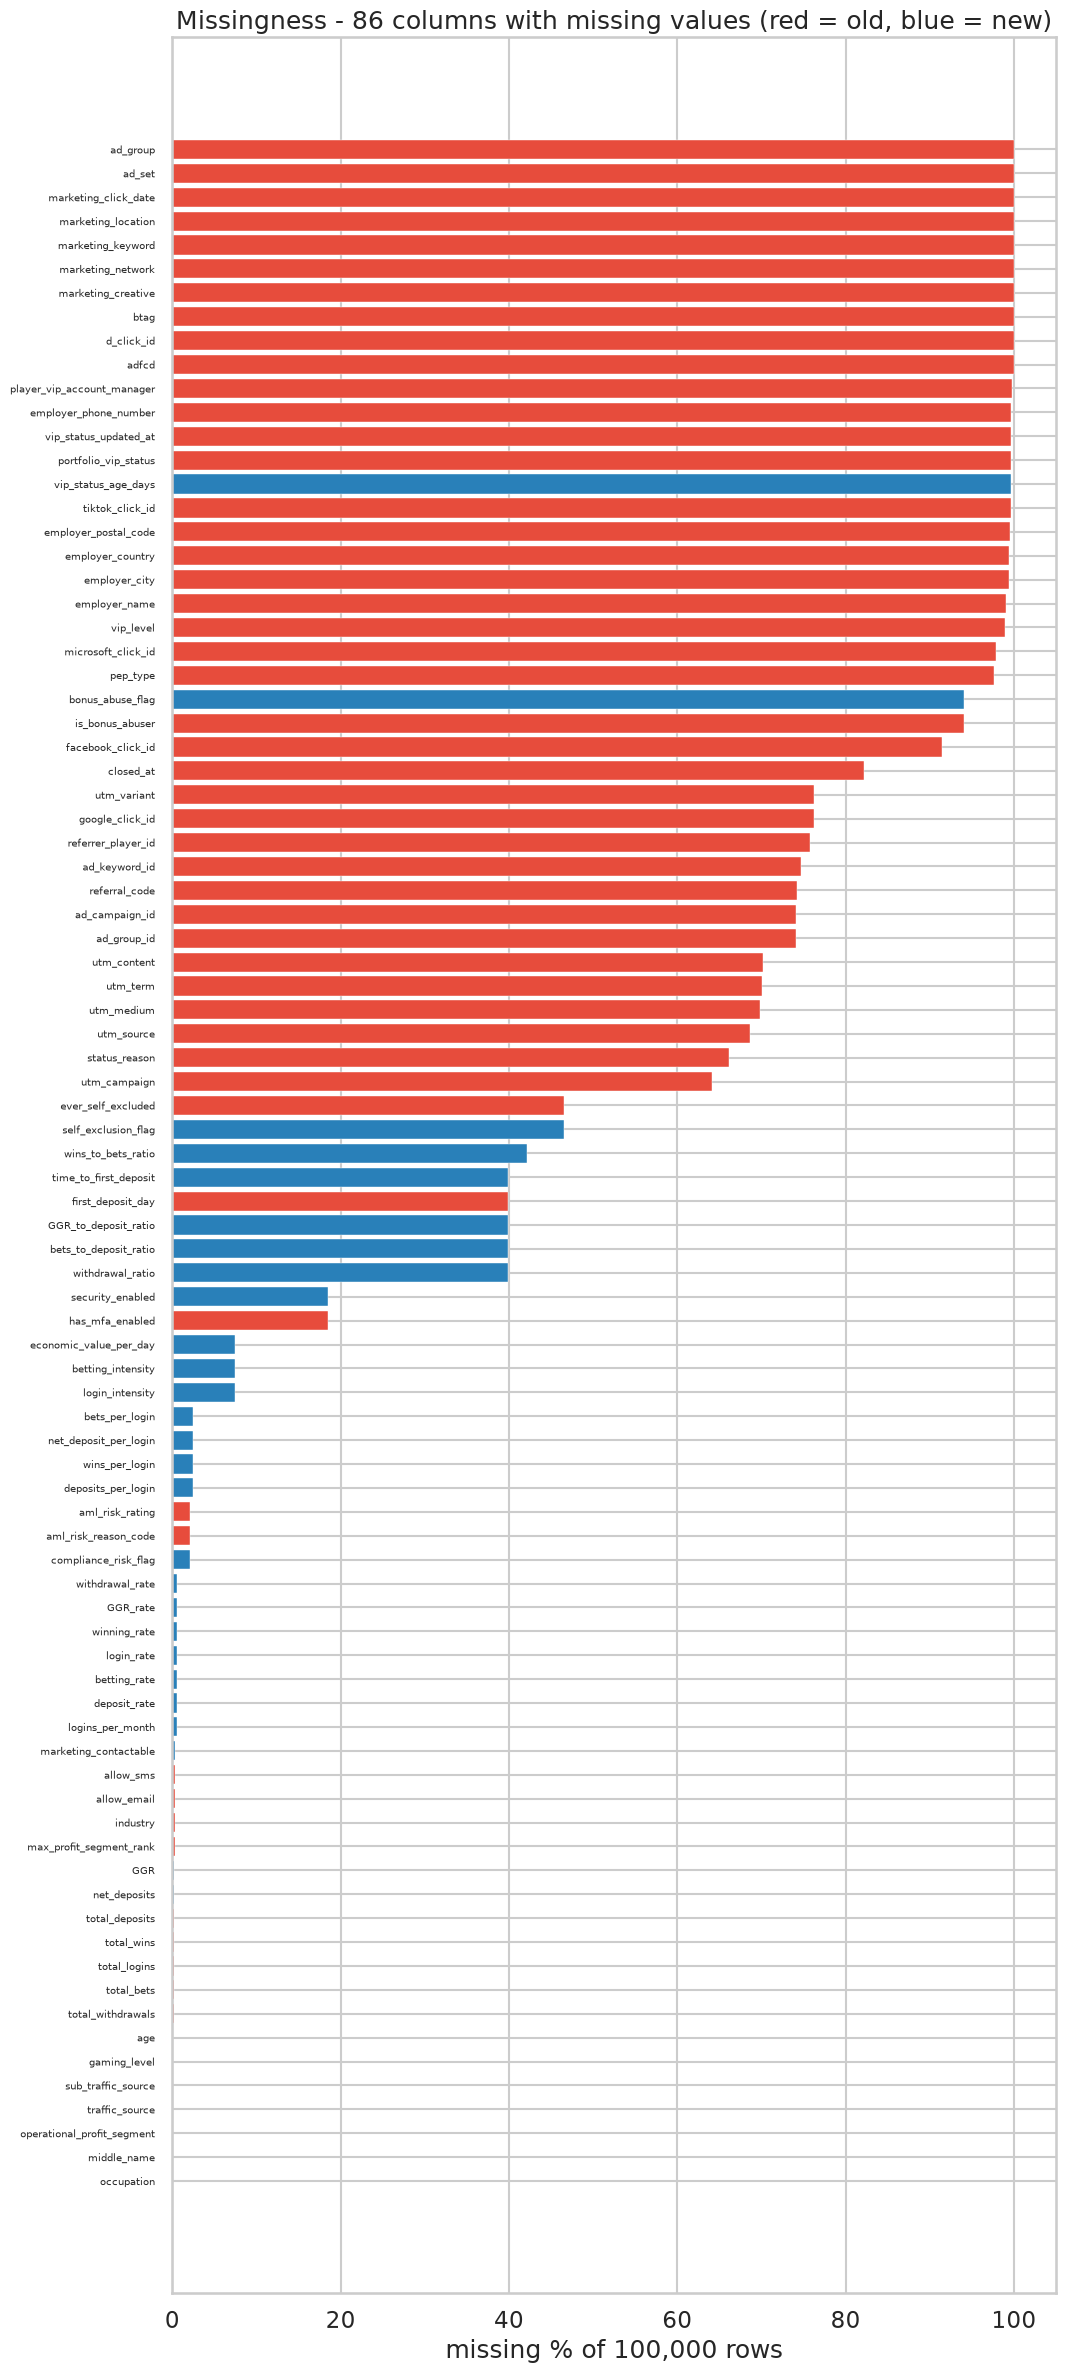

[saved] new_eda_output/missingness.png  (86 cols with missing values)


In [9]:
miss = combined.isna().mean() * 100
miss = miss[miss > 0].sort_values()
colors = ["#e74c3c" if origin[c] == "old" else "#2980b9" for c in miss.index]

fig, ax = plt.subplots(figsize=(11, max(6, len(miss) * 0.28)))
ax.barh(miss.index, miss.values, color=colors, edgecolor="white", linewidth=0.3)
ax.set_xlabel("missing % of 100,000 rows")
ax.set_title(f"Missingness - {len(miss)} columns with missing values "
             "(red = old, blue = new)")
if len(miss) > 15:
    ax.tick_params(axis="y", labelsize=7)
fig.tight_layout()
fig.savefig(f"{OUT}/missingness.png", dpi=120, bbox_inches="tight")
display(fig)
plt.close(fig)
print(f"[saved] {OUT}/missingness.png  ({len(miss)} cols with missing values)")

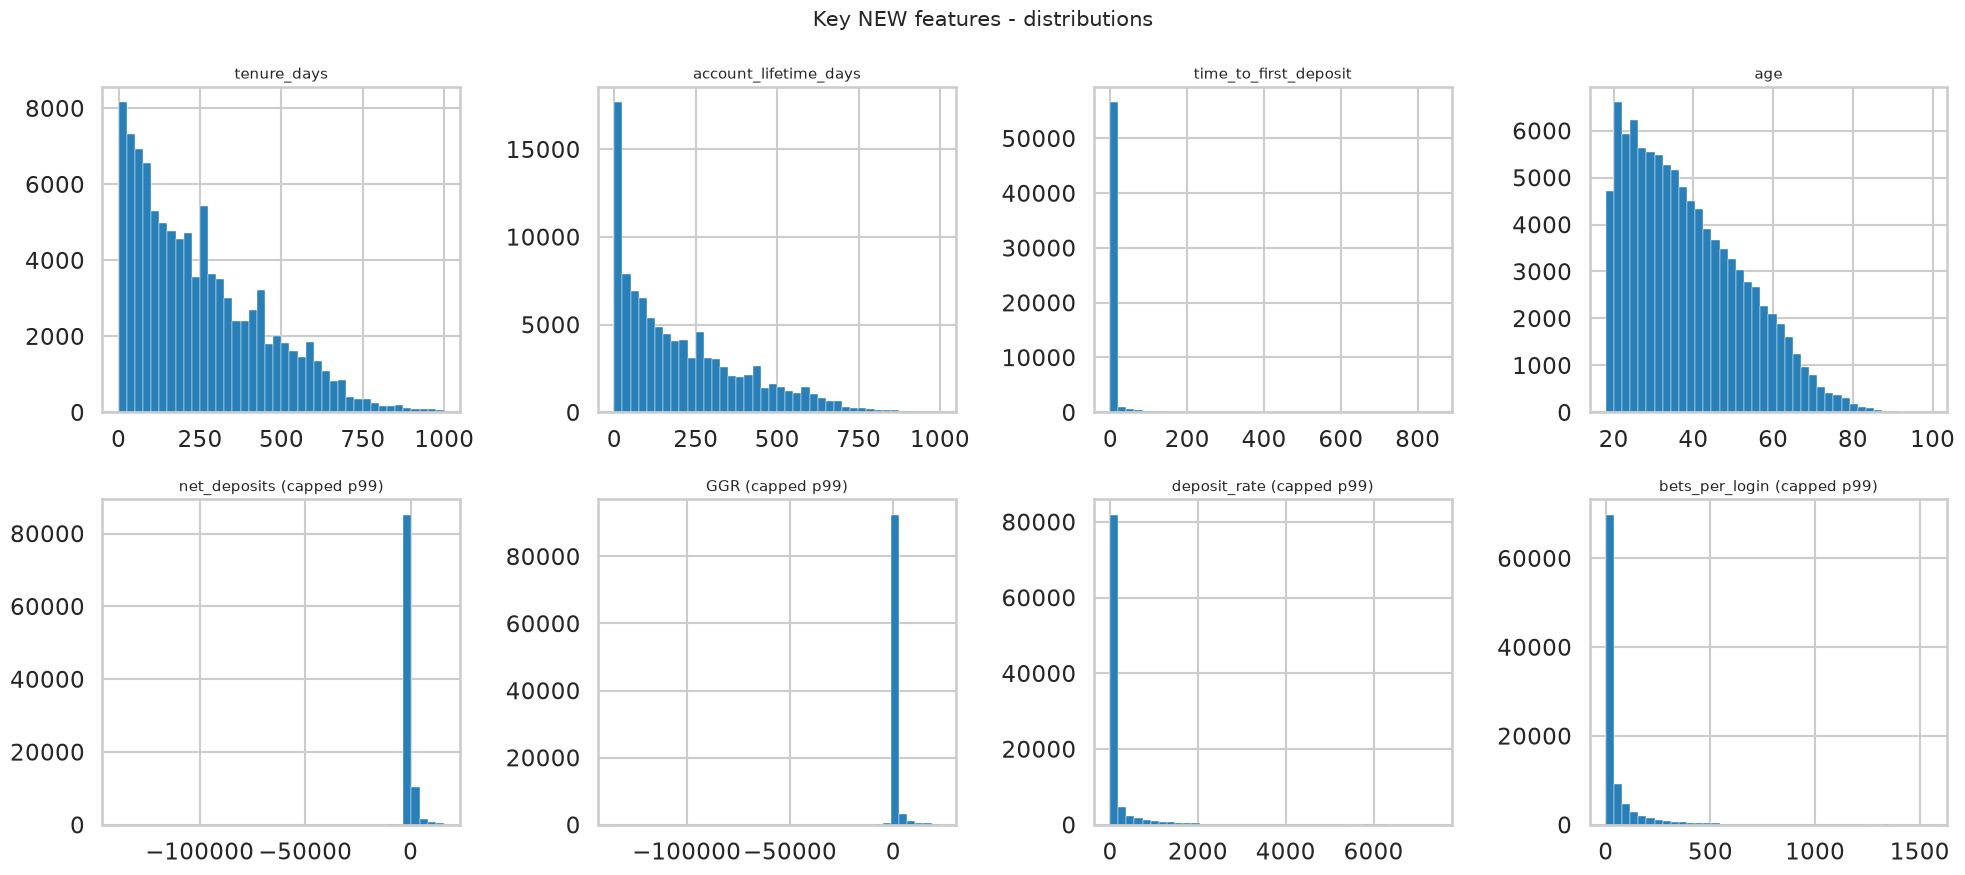

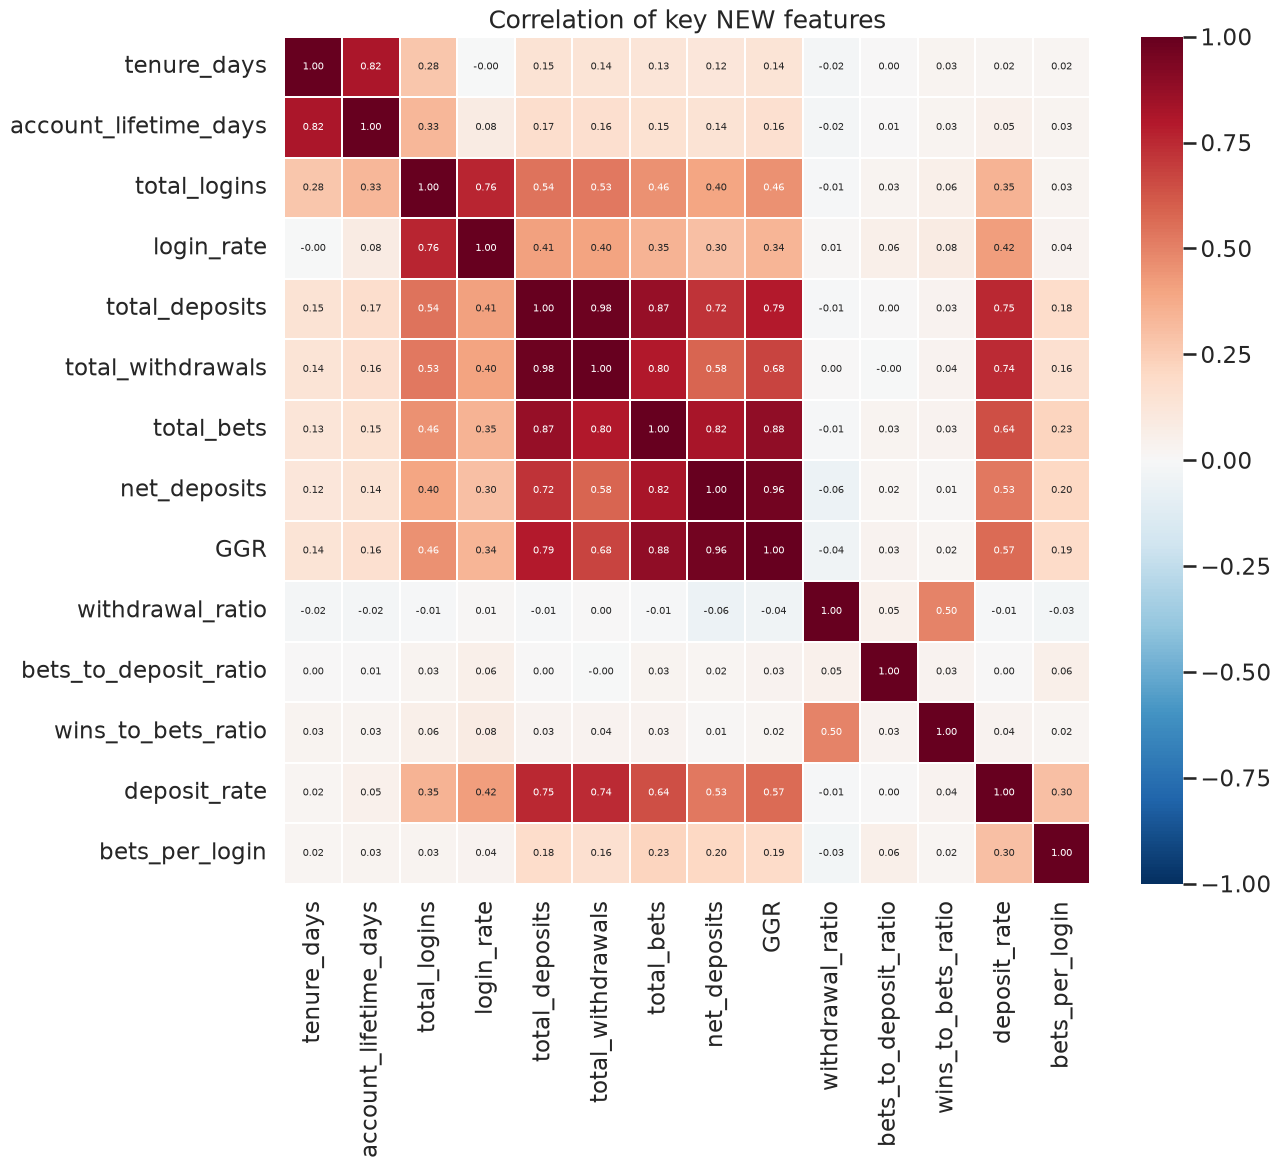

[saved] new_eda_output/new_feature_distributions.png
[saved] new_eda_output/new_feature_correlations.png


In [10]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
specs = [("tenure_days", None), ("account_lifetime_days", None),
         ("time_to_first_deposit", None), ("age", None),
         ("net_deposits", 0.99), ("GGR", 0.99),
         ("deposit_rate", 0.99), ("bets_per_login", 0.99)]
for ax, (c, q) in zip(axes.ravel(), specs):
    s = combined[c].dropna()
    if q:
        s = s[s <= s.quantile(q)]
    ax.hist(s, bins=40, color="#2980b9", edgecolor="white", linewidth=0.3)
    ax.set_title(c + (f" (capped p{int(q * 100)})" if q else ""), fontsize=11)
fig.suptitle("Key NEW features - distributions", fontsize=15)
fig.tight_layout()
fig.savefig(f"{OUT}/new_feature_distributions.png", dpi=120, bbox_inches="tight")
display(fig)
plt.close(fig)

key = ["tenure_days", "account_lifetime_days", "total_logins", "login_rate",
       "total_deposits", "total_withdrawals", "total_bets", "net_deposits",
       "GGR", "withdrawal_ratio", "bets_to_deposit_ratio", "wins_to_bets_ratio",
       "deposit_rate", "bets_per_login"]
corr = combined[key].corr()
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True,
            fmt=".2f", linewidths=0.3, ax=ax, annot_kws={"size": 7})
ax.set_title("Correlation of key NEW features")
fig.savefig(f"{OUT}/new_feature_correlations.png", dpi=120, bbox_inches="tight")
display(fig)
plt.close(fig)
print(f"[saved] {OUT}/new_feature_distributions.png")
print(f"[saved] {OUT}/new_feature_correlations.png")

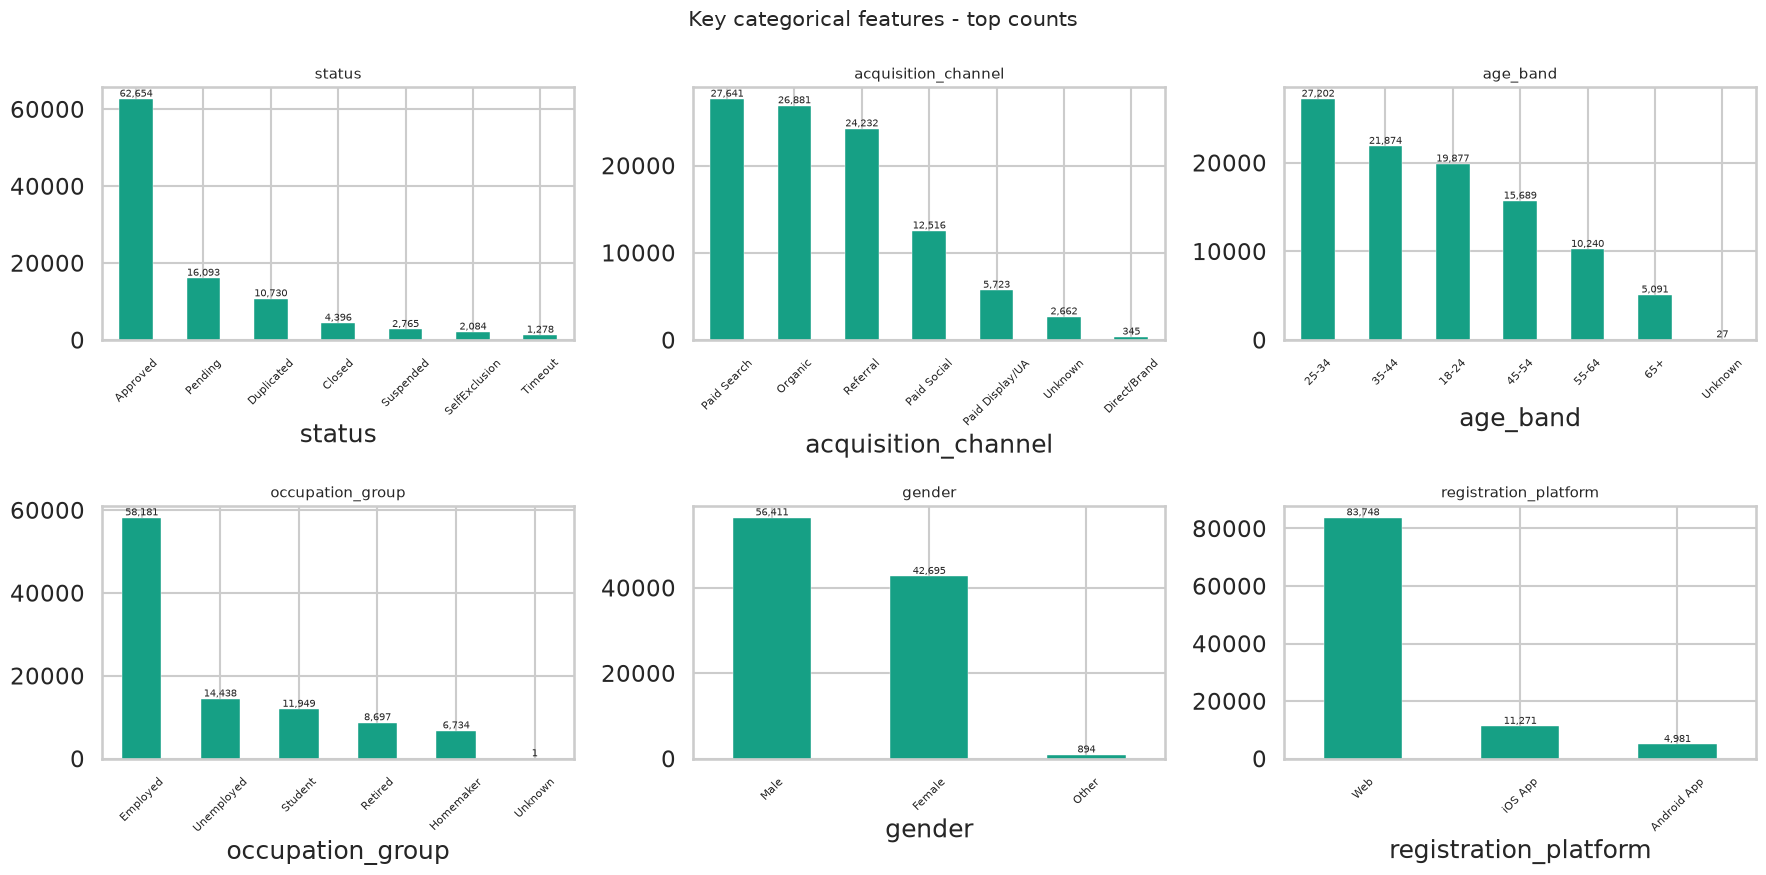

[saved] new_eda_output/categorical_counts.png
Done.


In [11]:
cats = ["status", "acquisition_channel", "age_band", "occupation_group",
        "gender", "registration_platform"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, c in zip(axes.ravel(), cats):
    vc = combined[c].fillna("(missing)").value_counts().head(12)
    vc.plot.bar(ax=ax, color="#16a085", edgecolor="white", linewidth=0.3)
    ax.set_title(c, fontsize=11)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    for x, v in zip(range(len(vc)), vc.values):
        ax.text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=7)
fig.suptitle("Key categorical features - top counts", fontsize=15)
fig.tight_layout()
fig.savefig(f"{OUT}/categorical_counts.png", dpi=120, bbox_inches="tight")
display(fig)
plt.close(fig)
print(f"[saved] {OUT}/categorical_counts.png")
print("Done.")

## Histograms — raw vs `log1p` transform

Eight heavily right-skewed features, shown twice: **raw (linear)** and after
**`log1p(x) = ln(1 + x)`**.

`log1p` requires `x >= 0` (asserted below — all eight features are non-negative),
keeps zeros at 0 (`log1p(0) = 0`), and compresses the right tail so the bulk of
the distribution becomes visible. Red dashed line = median; titles show skewness
before/after; the skew-reduction table prints at the end.

Outputs: `new_eda_output/hist_raw.png`, `new_eda_output/hist_log1p.png`

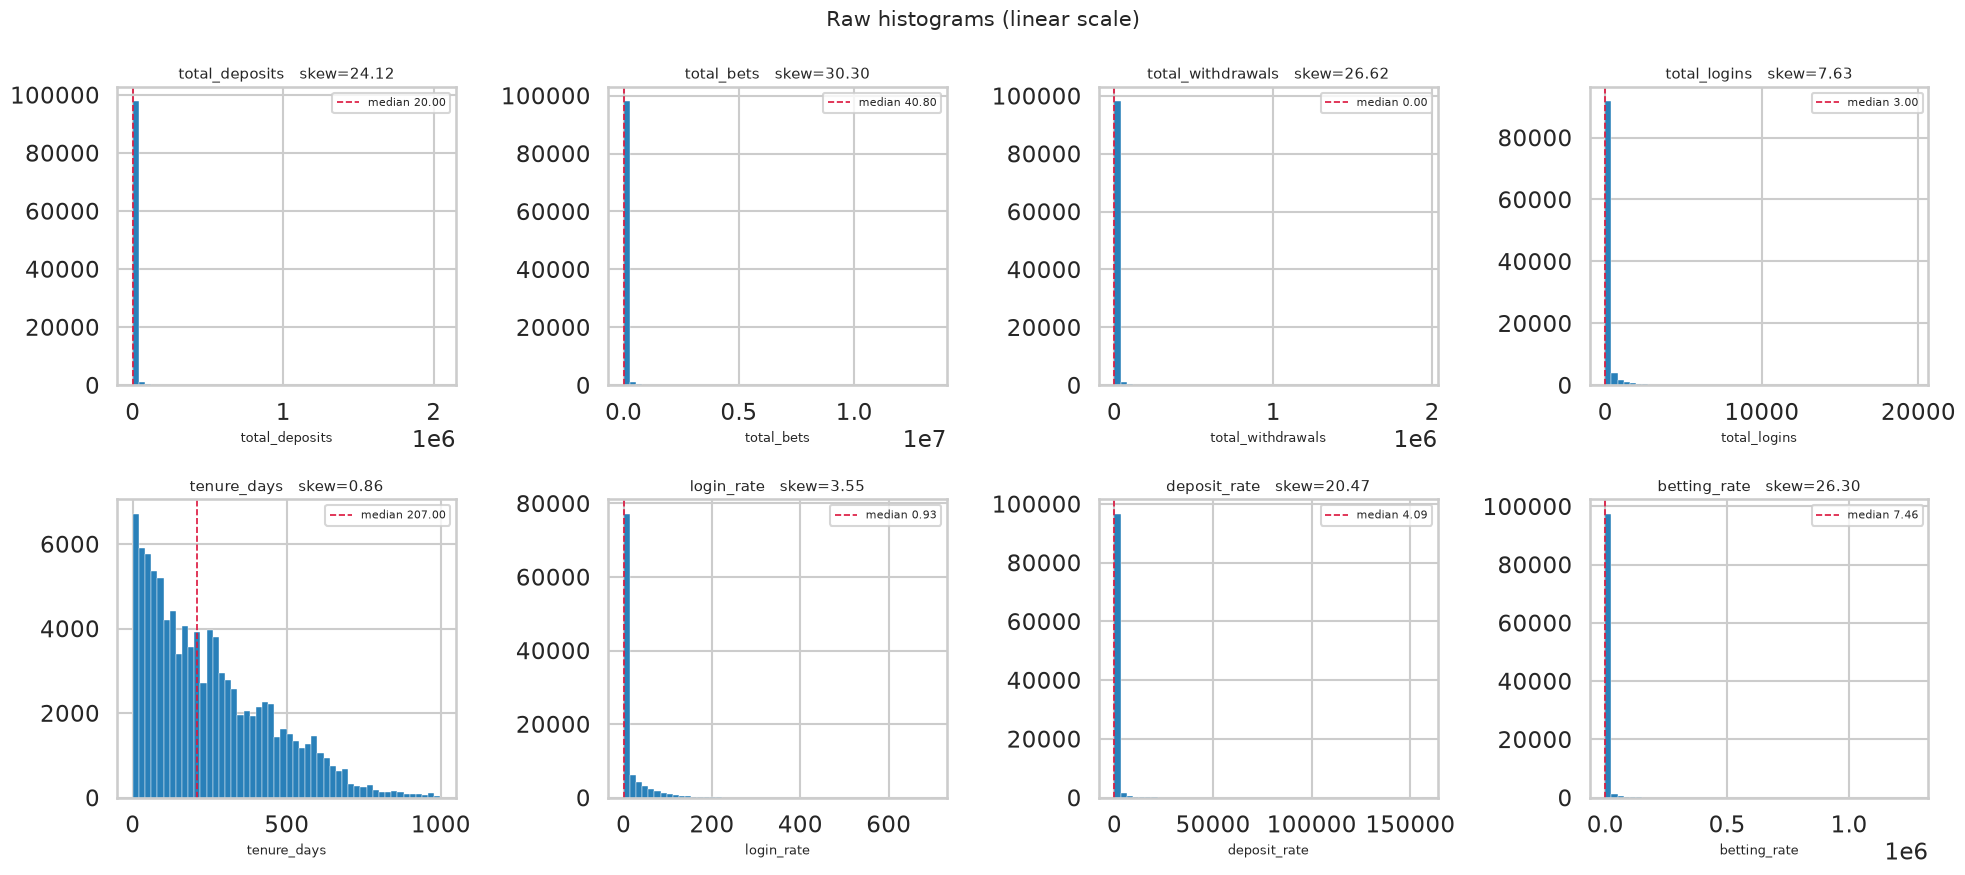

[saved] new_eda_output/hist_raw.png


In [12]:
LOG_FEATS = ["total_deposits", "total_bets", "total_withdrawals", "total_logins",
             "tenure_days", "login_rate", "deposit_rate", "betting_rate"]

neg = {c: int((combined[c] < 0).sum()) for c in LOG_FEATS}
assert not any(neg.values()), f"log1p needs x >= 0, negatives found: {neg}"

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, c in zip(axes.ravel(), LOG_FEATS):
    s = combined[c].dropna()
    ax.hist(s, bins=50, color="#2980b9", edgecolor="white", linewidth=0.3)
    med = s.median()
    ax.axvline(med, color="crimson", linestyle="--", linewidth=1.2,
               label=f"median {med:,.2f}")
    ax.set_title(f"{c}   skew={s.skew():.2f}", fontsize=11)
    ax.set_xlabel(c, fontsize=9)
    ax.legend(fontsize=8)
fig.suptitle("Raw histograms (linear scale)", fontsize=15)
fig.tight_layout()
fig.savefig(f"{OUT}/hist_raw.png", dpi=120, bbox_inches="tight")
display(fig)
plt.close(fig)
print(f"[saved] {OUT}/hist_raw.png")

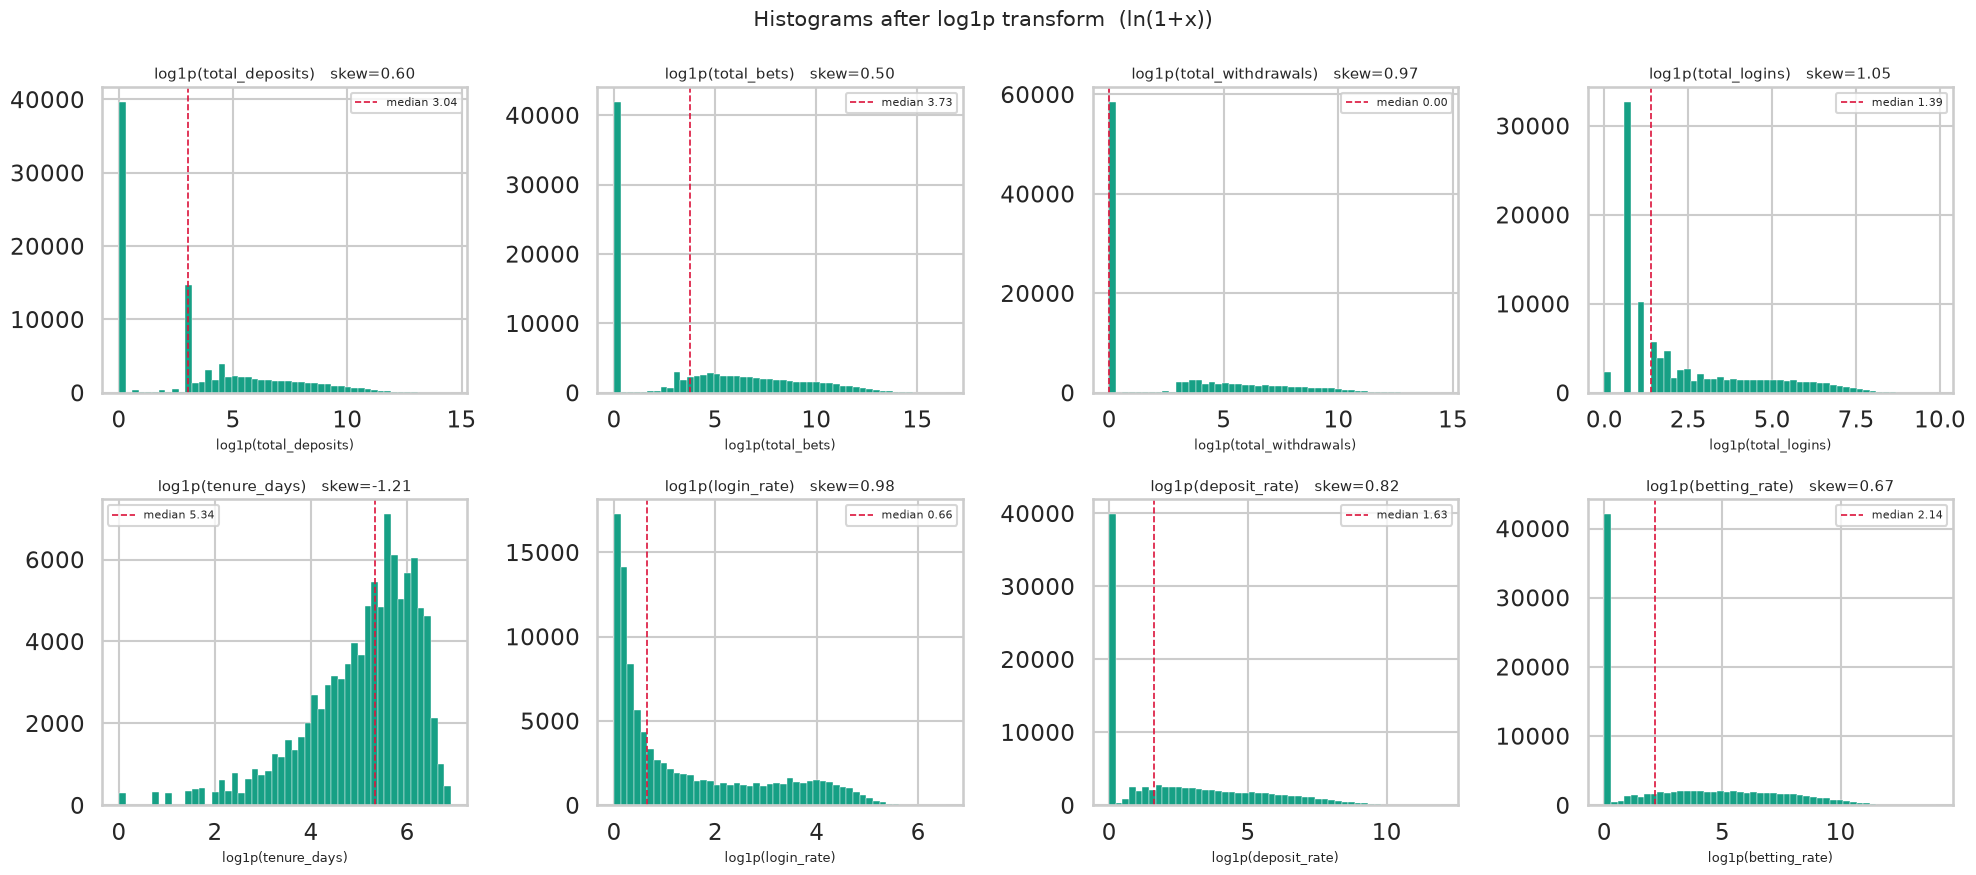

skewness before / after log1p:


,skew_raw,skew_log1p,reduction_%
total_deposits,24.12,0.60,97.5
total_bets,30.30,0.50,98.3
total_withdrawals,26.62,0.97,96.4
total_logins,7.63,1.05,86.2
tenure_days,0.86,-1.21,-40.7
login_rate,3.55,0.98,72.4
deposit_rate,20.47,0.82,96.0
betting_rate,26.30,0.67,97.5


[saved] new_eda_output/hist_log1p.png


In [13]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
skews = {}
for ax, c in zip(axes.ravel(), LOG_FEATS):
    s = combined[c].dropna()
    ls = np.log1p(s)
    ax.hist(ls, bins=50, color="#16a085", edgecolor="white", linewidth=0.3)
    med = ls.median()
    ax.axvline(med, color="crimson", linestyle="--", linewidth=1.2,
               label=f"median {med:,.2f}")
    ax.set_title(f"log1p({c})   skew={ls.skew():.2f}", fontsize=11)
    ax.set_xlabel(f"log1p({c})", fontsize=9)
    ax.legend(fontsize=8)
    skews[c] = {"skew_raw": s.skew(), "skew_log1p": ls.skew()}
fig.suptitle("Histograms after log1p transform  (ln(1+x))", fontsize=15)
fig.tight_layout()
fig.savefig(f"{OUT}/hist_log1p.png", dpi=120, bbox_inches="tight")
display(fig)
plt.close(fig)

skew_df = pd.DataFrame(skews).T.round(2)
skew_df["reduction_%"] = (1 - skew_df["skew_log1p"].abs() /
                          skew_df["skew_raw"].abs()).mul(100).round(1)
print("skewness before / after log1p:")
display(skew_df)
print(f"[saved] {OUT}/hist_log1p.png")

## Categorical frequency analysis

For `status`, `country`, `gender`, `gaming_level`, `traffic_source`,
`sub_traffic_source`, `registration_platform`, `aml_risk_rating`:

| metric | definition |
|---|---|
| **frequency** | number of players (rows) in the category; missing shown as its own `(missing)` row |
| **percentage** | frequency / 100,000 × 100 (full-row denominator, same as the stats report) |
| **number of categories** | distinct non-missing values (`n_categories`) |
| **rare-category %** | a category is **rare** if it covers **< 1% of players** (< 1,000 rows). Reported both ways: `rare_cat_%` = share of *categories* that are rare, `rare_rows_%` = share of *players* sitting in rare categories |

Outputs → `new_eda_output/categorical_frequencies.csv` (long: feature, category,
frequency, percentage, is_rare) and `categorical_summary.csv` (one row per feature).

In [14]:
RARE_FEATS = ["status", "country", "gender", "gaming_level", "traffic_source",
              "sub_traffic_source", "registration_platform", "aml_risk_rating"]
RARE_PCT = 1.0  # rare = covers < 1% of players (< 1,000 rows)

freq_tables, summary_rows = {}, []

for c in RARE_FEATS:
    s = combined[c]
    vc = s.value_counts(dropna=False)
    tab = pd.DataFrame({"frequency": vc})
    tab.index = ["(missing)" if pd.isna(v) else v for v in tab.index]
    tab["percentage"] = tab["frequency"] / len(combined) * 100
    tab["is_rare"] = (tab.index != "(missing)") & (tab["percentage"] < RARE_PCT)

    n_cats = int((tab.index != "(missing)").sum())
    miss_pct = float(tab.loc[tab.index == "(missing)", "percentage"].sum())
    rare = tab[tab["is_rare"]]
    summary_rows.append({
        "feature": c,
        "n_categories": n_cats,
        "missing_%": round(miss_pct, 4),
        "rare_cats(<1%)": int(len(rare)),
        "rare_cat_%": round(len(rare) / n_cats * 100, 2) if n_cats else np.nan,
        "rare_rows_%": round(float(rare["percentage"].sum()), 2),
    })
    freq_tables[c] = tab

    print(f"{c}  |  categories: {n_cats}  |  rare (<1%): {len(rare)} "
          f"= {summary_rows[-1]['rare_cat_%']}% of categories, "
          f"{summary_rows[-1]['rare_rows_%']}% of players  |  "
          f"missing: {round(miss_pct, 4)}%")
    display(tab.round(4))
    print()

status  |  categories: 7  |  rare (<1%): 0 = 0.0% of categories, 0.0% of players  |  missing: 0.0%


,frequency,percentage,is_rare
Approved,62654,62.654,False
Pending,16093,16.093,False
Duplicated,10730,10.730,False
Closed,4396,4.396,False
Suspended,2765,2.765,False
SelfExclusion,2084,2.084,False
Timeout,1278,1.278,False



country  |  categories: 2  |  rare (<1%): 1 = 50.0% of categories, 0.0% of players  |  missing: 0.0%


,frequency,percentage,is_rare
Canada,99998,99.998,False
United States,2,0.002,True



gender  |  categories: 3  |  rare (<1%): 1 = 33.33% of categories, 0.89% of players  |  missing: 0.0%


...

,frequency,percentage,is_rare
Organic,26701,26.701,False
Google,25514,25.514,False
Referred,16798,16.798,False
Facebook,8823,8.823,False
Referred From Paid Traffic,7434,7.434,False
Liftoff,3477,3.477,False
Unclassified UTM,2640,2.640,False
Moloco,2231,2.231,False
Microsoft,2113,2.113,False
TikTok,1728,1.728,False



registration_platform  |  categories: 3  |  rare (<1%): 0 = 0.0% of categories, 0.0% of players  |  missing: 0.0%


,frequency,percentage,is_rare
Web,83748,83.748,False
iOS App,11271,11.271,False
Android App,4981,4.981,False



aml_risk_rating  |  categories: 4  |  rare (<1%): 3 = 75.0% of categories, 0.96% of players  |  missing: 2.136%


,frequency,percentage,is_rare
Low,96903,96.903,False
(missing),2136,2.136,False
Moderate,646,0.646,True
High,265,0.265,True
Extreme,50,0.050,True


In [15]:
categorical_summary = pd.DataFrame(summary_rows)
print("summary across the 8 features:")
display(categorical_summary)

long = (pd.concat(freq_tables, names=["feature"])
        .rename_axis(["feature", "category"])
        .reset_index())
long.to_csv(f"{OUT}/categorical_frequencies.csv", index=False)
categorical_summary.to_csv(f"{OUT}/categorical_summary.csv", index=False)
print(f"[saved] {OUT}/categorical_frequencies.csv  ({long.shape[0]} rows)")
print(f"[saved] {OUT}/categorical_summary.csv  ({categorical_summary.shape[0]} rows)")

summary across the 8 features:


,feature,n_categories,missing_%,rare_cats(<1%),rare_cat_%,rare_rows_%
0,status,7,0.000,0,0.00,0.00
1,country,2,0.000,1,50.00,0.00
2,gender,3,0.000,1,33.33,0.89
3,gaming_level,2,0.017,1,50.00,0.03
4,traffic_source,25,0.008,14,56.00,0.87
5,sub_traffic_source,28,0.008,17,60.71,0.86
6,registration_platform,3,0.000,0,0.00,0.00
7,aml_risk_rating,4,2.136,3,75.00,0.96


[saved] new_eda_output/categorical_frequencies.csv  (78 rows)
[saved] new_eda_output/categorical_summary.csv  (8 rows)


## Bivariate analysis — segmentation-relevant pairs

Six relationships, each with **Pearson** (linear, sensitive to skew/outliers),
**Spearman** (rank-based, monotonic — the right choice for these skewed money
variables) and `pearson_log1p` (Pearson after `ln(1+x)`, for reference):

1. `tenure_days` ↔ `total_deposits`
2. `tenure_days` ↔ `total_bets`
3. `total_deposits` ↔ `total_bets`
4. `total_deposits` ↔ `total_withdrawals`
5. `total_logins` ↔ `total_bets`
6. `age` ↔ `total_deposits`

Correlations use pairwise-complete rows (n shown per pair; missing: 214 rows
for `total_logins`, 27 for `age`). With n ≈ 100,000 every coefficient is
significant at p < 0.001, so p-values are not reported. Spearman is computed as
Pearson on average ranks (identical result, no scipy dependency).

Outputs → `new_eda_output/bivariate_correlations.csv`,
`bivariate_scatter_raw.png`, `bivariate_scatter_log1p.png`

In [16]:
BIVAR_PAIRS = [("tenure_days", "total_deposits"),
               ("tenure_days", "total_bets"),
               ("total_deposits", "total_bets"),
               ("total_deposits", "total_withdrawals"),
               ("total_logins", "total_bets"),
               ("age", "total_deposits")]

rows = []
for x, y in BIVAR_PAIRS:
    d = combined[[x, y]].dropna()
    rows.append({"pair": f"{x} vs {y}", "x": x, "y": y, "n": len(d),
                 "pearson": d[x].corr(d[y]),
                 "spearman": d[x].rank().corr(d[y].rank()),
                 "pearson_log1p": np.log1p(d[x]).corr(np.log1p(d[y]))})

bivar = pd.DataFrame(rows).set_index("pair")
print("Pearson (linear) vs Spearman (monotonic, robust to skew):")
display(bivar[["n", "pearson", "spearman", "pearson_log1p"]].round(3))
bivar.to_csv(f"{OUT}/bivariate_correlations.csv")
print(f"[saved] {OUT}/bivariate_correlations.csv")

Pearson (linear) vs Spearman (monotonic, robust to skew):


,n,pearson,spearman,pearson_log1p
pair,,,,
tenure_days vs total_deposits,99786,0.146,0.131,0.155
tenure_days vs total_bets,99786,0.130,0.134,0.148
total_deposits vs total_bets,99786,0.871,0.961,0.966
total_deposits vs total_withdrawals,99786,0.983,0.807,0.857
total_logins vs total_bets,99786,0.457,0.860,0.863
age vs total_deposits,99761,0.047,0.032,0.043


[saved] new_eda_output/bivariate_correlations.csv


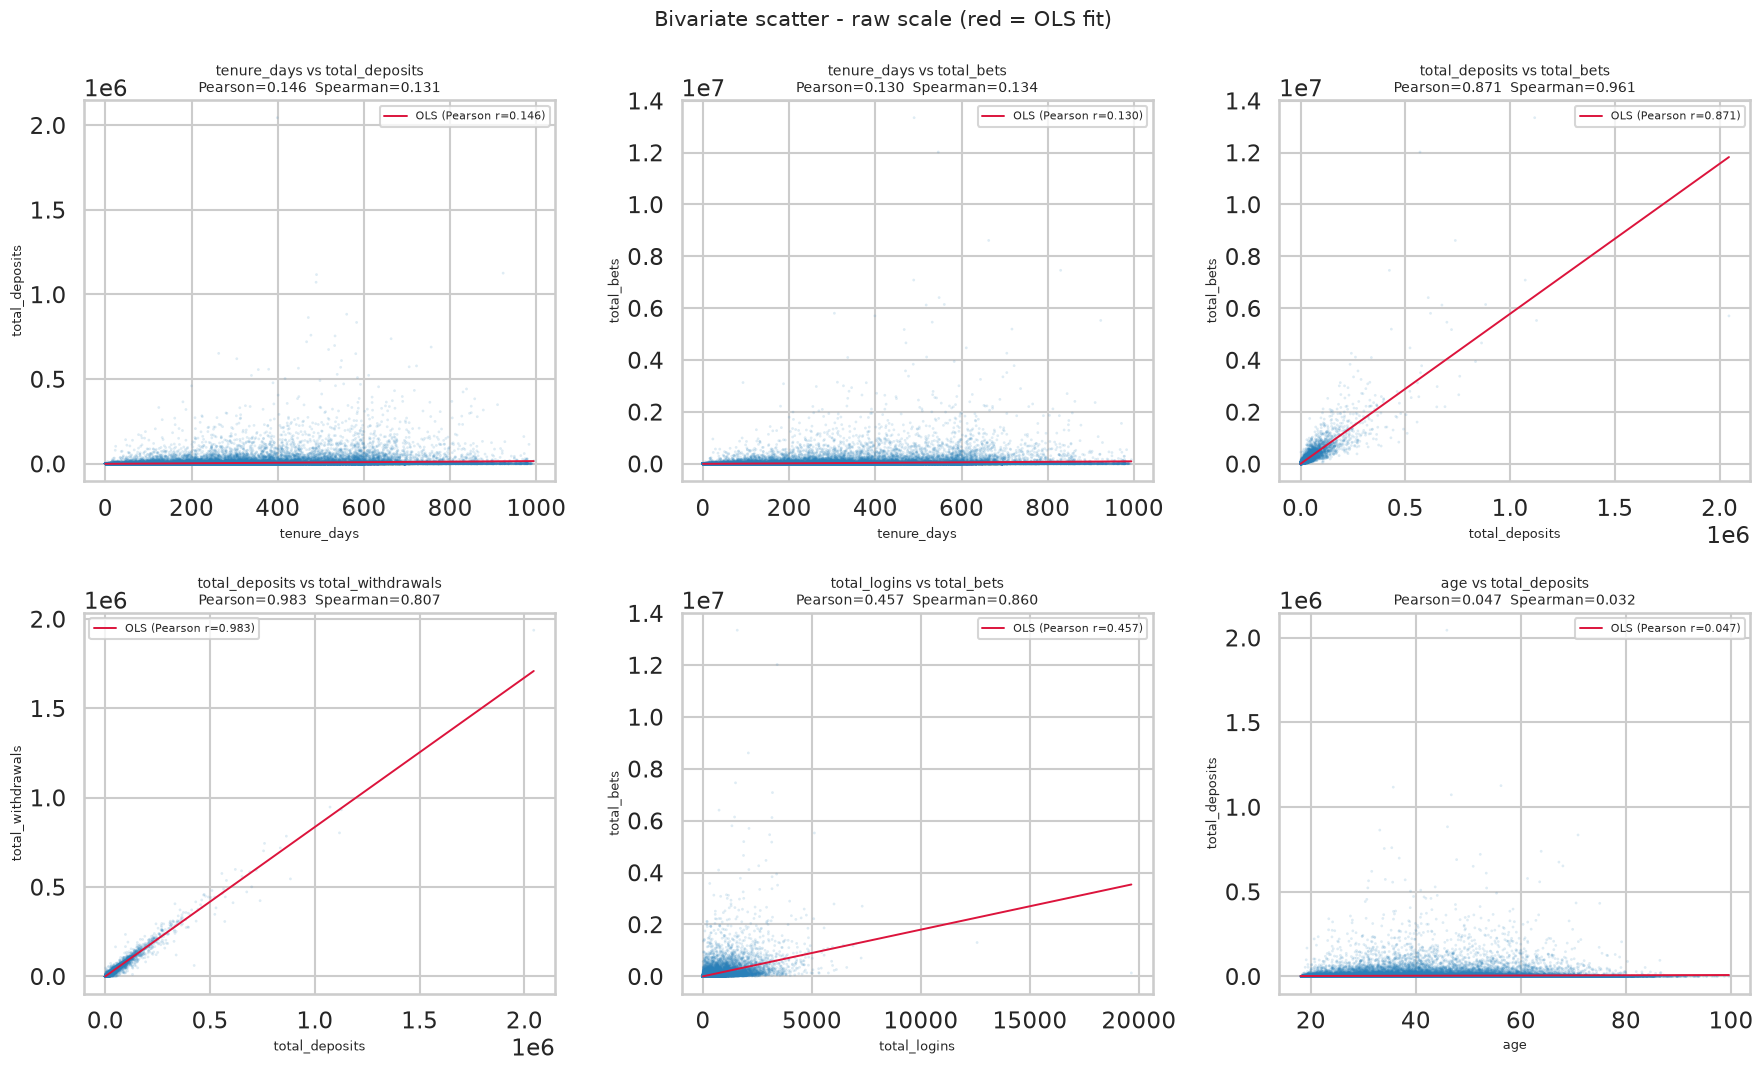

[saved] new_eda_output/bivariate_scatter_raw.png


In [17]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, (x, y) in zip(axes.ravel(), BIVAR_PAIRS):
    d = combined[[x, y]].dropna()
    r = d[x].corr(d[y])
    rho = d[x].rank().corr(d[y].rank())
    ax.scatter(d[x], d[y], s=4, alpha=0.15, color="#2980b9",
               edgecolor="none")
    slope, intercept = np.polyfit(d[x], d[y], 1)
    xs = np.linspace(d[x].min(), d[x].max(), 50)
    ax.plot(xs, slope * xs + intercept, color="crimson", linewidth=1.4,
            label=f"OLS (Pearson r={r:.3f})")
    ax.set_xlabel(x, fontsize=9)
    ax.set_ylabel(y, fontsize=9)
    ax.set_title(f"{x} vs {y}\nPearson={r:.3f}  Spearman={rho:.3f}",
                 fontsize=10)
    ax.legend(fontsize=8)
fig.suptitle("Bivariate scatter - raw scale (red = OLS fit)", fontsize=15)
fig.tight_layout()
fig.savefig(f"{OUT}/bivariate_scatter_raw.png", dpi=120, bbox_inches="tight")
display(fig)
plt.close(fig)
print(f"[saved] {OUT}/bivariate_scatter_raw.png")

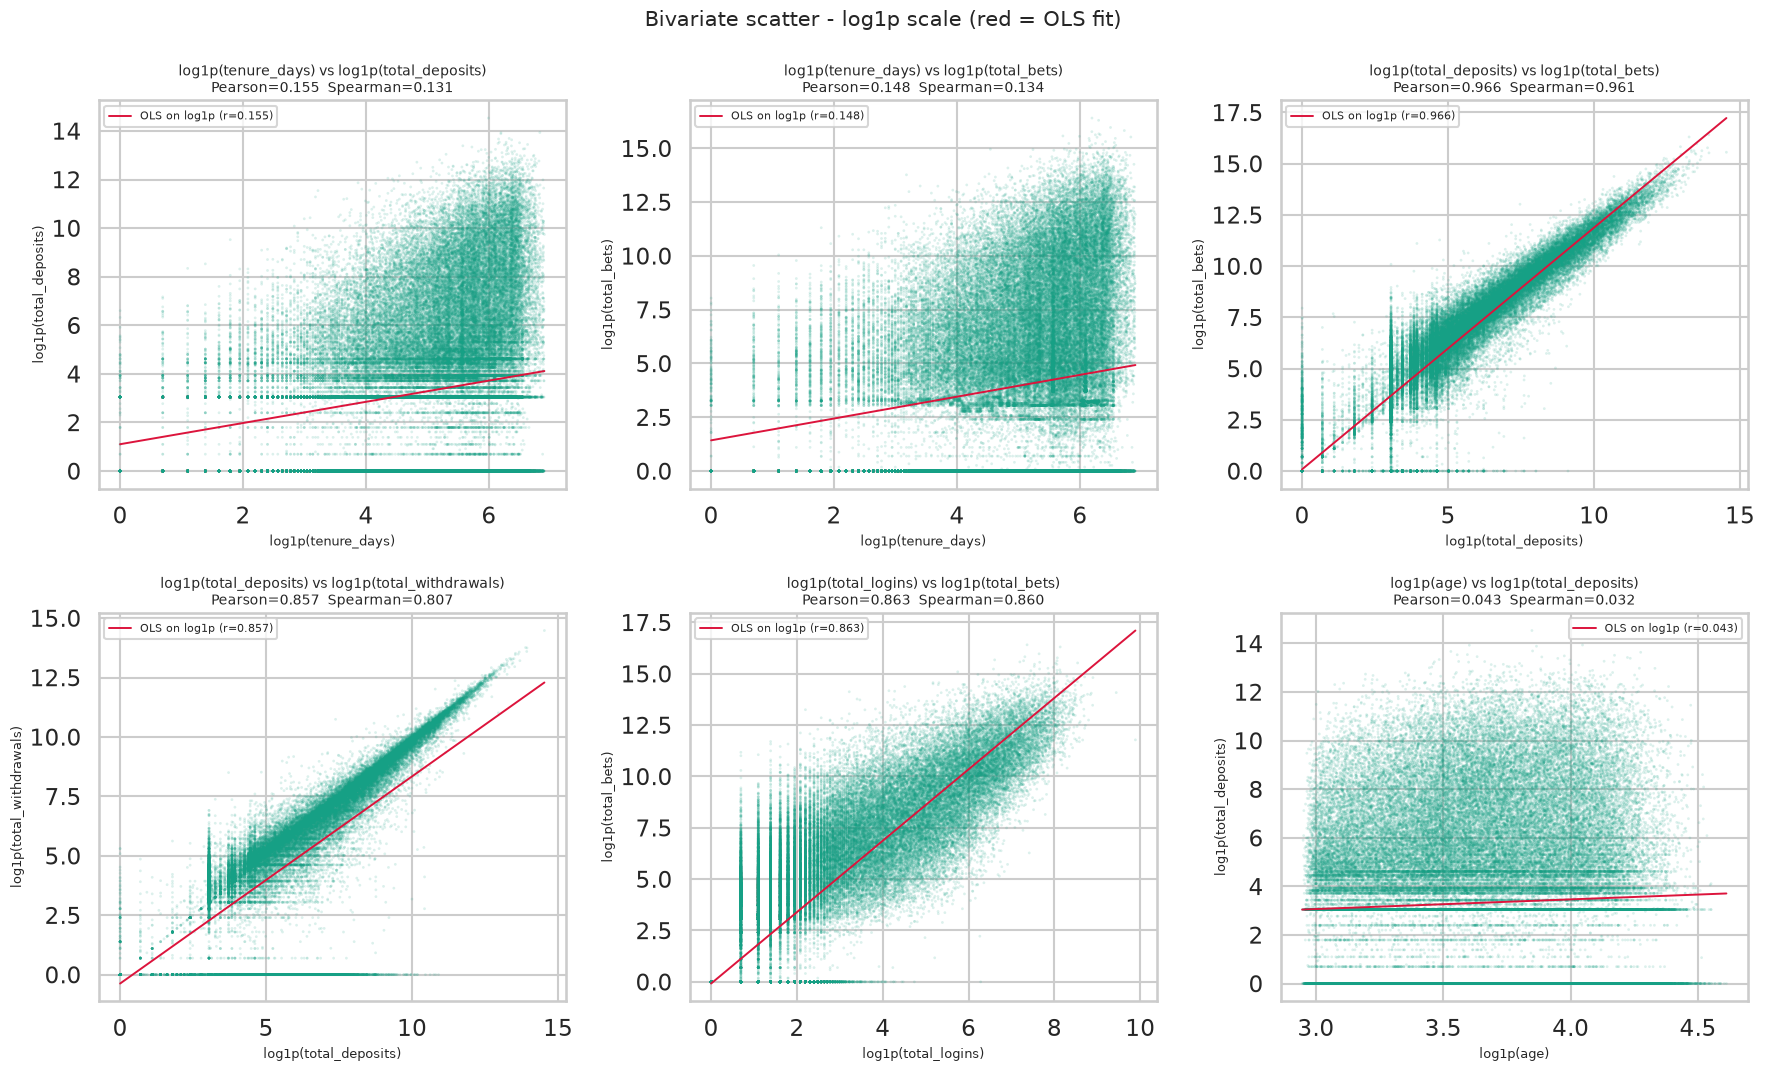

[saved] new_eda_output/bivariate_scatter_log1p.png


In [18]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, (x, y) in zip(axes.ravel(), BIVAR_PAIRS):
    d = combined[[x, y]].dropna()
    lx, ly = np.log1p(d[x]), np.log1p(d[y])
    r = lx.corr(ly)
    rho = d[x].rank().corr(d[y].rank())
    ax.scatter(lx, ly, s=4, alpha=0.15, color="#16a085", edgecolor="none")
    slope, intercept = np.polyfit(lx, ly, 1)
    xs = np.linspace(lx.min(), lx.max(), 50)
    ax.plot(xs, slope * xs + intercept, color="crimson", linewidth=1.4,
            label=f"OLS on log1p (r={r:.3f})")
    ax.set_xlabel(f"log1p({x})", fontsize=9)
    ax.set_ylabel(f"log1p({y})", fontsize=9)
    ax.set_title(f"log1p({x}) vs log1p({y})\nPearson={r:.3f}  "
                 f"Spearman={rho:.3f}", fontsize=10)
    ax.legend(fontsize=8)
fig.suptitle("Bivariate scatter - log1p scale (red = OLS fit)", fontsize=15)
fig.tight_layout()
fig.savefig(f"{OUT}/bivariate_scatter_log1p.png", dpi=120, bbox_inches="tight")
display(fig)
plt.close(fig)
print(f"[saved] {OUT}/bivariate_scatter_log1p.png")

## Clustering matrix — decorrelated 2-variable transform

`Spearman(total_deposits, total_bets) = 0.961` → the two monetary variables are
near-duplicates in rank space. Following the segmentation recipe, the clustering
matrix keeps **one scale variable** and **one intensity ratio** instead:

```
monetary_scale   = log1p(total_deposits)      # compressed money scale, ~Gaussian-ish
betting_intensity = total_bets / total_deposits   # wagering turnover per $ deposited
```

instead of the raw pair `(total_deposits, total_bets)`.

**Naming note:** `player_features.csv` already contains a *different* column called
`betting_intensity` (= `total_bets / account_lifetime_days`, bets per day). The ratio
defined here is the same quantity as `bets_to_deposit_ratio`. The matrix below is a
**separate DataFrame** (`clustering_matrix`); `combined` is not modified.

**Edge cases (deposits = 0)**

| case | rows | treatment |
|---|---:|---|
| deposits = 0 **and** bets = 0 | 39,096 | `betting_intensity = 0` (no wagering on no money — defined as 0) |
| deposits = 0 **and** bets > 0 | 622 | `NaN` (turnover per deposit is undefined; free-play/bonus betting) |
| economic totals missing | 214 | `NaN` |
| deposits > 0 | 60,282 | strict `bets / deposits` |

Coverage: **99,164 / 100,000 rows complete** (99.2%) — vs 60.1% for the strict
ratio. Strict `bets/deposits` also already exists as `bets_to_deposit_ratio`.

Outputs → `new_eda_output/clustering_matrix.csv` (player_id + 2 columns),
`clustering_matrix.png`

In [19]:
monetary_scale = np.log1p(combined["total_deposits"])

betting_intensity = combined["total_bets"] / combined["total_deposits"]
betting_intensity = betting_intensity.replace([np.inf, -np.inf], np.nan)
both_zero = combined["total_deposits"].eq(0) & combined["total_bets"].eq(0)
betting_intensity[both_zero] = 0.0

clustering_matrix = pd.DataFrame(
    {"player_id": combined["player_id"],
     "monetary_scale": monetary_scale,
     "betting_intensity": betting_intensity})

print("clustering matrix:")
display(clustering_matrix[["monetary_scale", "betting_intensity"]].describe().round(3))

complete = clustering_matrix[["monetary_scale", "betting_intensity"]].dropna()
print(f"complete rows: {len(complete):,} ({len(complete) / len(clustering_matrix) * 100:.1f}%)"
      f"  |  dropped: {len(clustering_matrix) - len(complete):,} "
      f"(622 deposit-free betting + 214 missing totals)")

def pair_corr(a, b, label):
    d = pd.DataFrame({"a": a, "b": b}).dropna()
    return {"pair": label, "n": len(d),
            "pearson": d["a"].corr(d["b"]),
            "spearman": d["a"].rank().corr(d["b"].rank())}

cmp = pd.DataFrame([
    pair_corr(combined["total_deposits"], combined["total_bets"],
              "raw: total_deposits, total_bets"),
    pair_corr(clustering_matrix["monetary_scale"],
              clustering_matrix["betting_intensity"],
              "new: monetary_scale, betting_intensity"),
]).set_index("pair")
print("decorrelation check (Spearman of the pair):")
display(cmp.round(3))

clustering_matrix.to_csv(f"{OUT}/clustering_matrix.csv", index=False)
print(f"[saved] {OUT}/clustering_matrix.csv  ({clustering_matrix.shape})")

clustering matrix:


,monetary_scale,betting_intensity
count,99786.000,99164.000
mean,3.310,3.467
std,3.299,11.479
min,0.000,0.000
25%,0.000,0.000
50%,3.045,1.264
75%,5.595,4.697
max,14.531,1329.418


complete rows: 99,164 (99.2%)  |  dropped: 836 (622 deposit-free betting + 214 missing totals)
decorrelation check (Spearman of the pair):


,n,pearson,spearman
pair,,,
"raw: total_deposits, total_bets",99786,0.871,0.961
"new: monetary_scale, betting_intensity",99164,0.202,0.821


[saved] new_eda_output/clustering_matrix.csv  ((100000, 3))


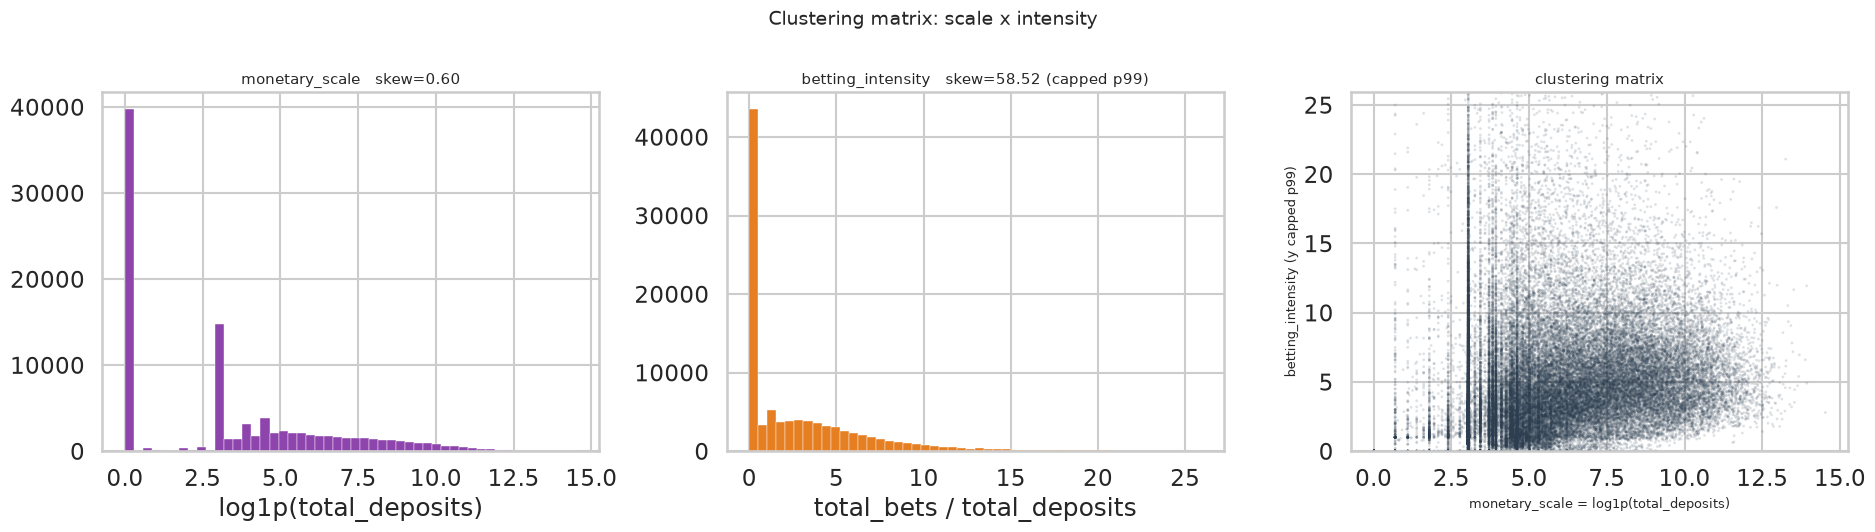

[saved] new_eda_output/clustering_matrix.png
Done.


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

s = clustering_matrix["monetary_scale"].dropna()
axes[0].hist(s, bins=50, color="#8e44ad", edgecolor="white", linewidth=0.3)
axes[0].set_title(f"monetary_scale   skew={s.skew():.2f}", fontsize=11)
axes[0].set_xlabel("log1p(total_deposits)")

b = clustering_matrix["betting_intensity"].dropna()
bcap = b.quantile(0.99)
axes[1].hist(b[b <= bcap], bins=50, color="#e67e22", edgecolor="white",
             linewidth=0.3)
axes[1].set_title(f"betting_intensity   skew={b.skew():.2f} (capped p99)",
                  fontsize=11)
axes[1].set_xlabel("total_bets / total_deposits")

cm = clustering_matrix.dropna()
axes[2].scatter(cm["monetary_scale"], cm["betting_intensity"], s=4,
                alpha=0.15, color="#2c3e50", edgecolor="none")
axes[2].set_ylim(0, cm["betting_intensity"].quantile(0.99))
axes[2].set_xlabel("monetary_scale = log1p(total_deposits)", fontsize=9)
axes[2].set_ylabel("betting_intensity (y capped p99)", fontsize=9)
axes[2].set_title("clustering matrix", fontsize=11)

fig.suptitle("Clustering matrix: scale x intensity", fontsize=14)
fig.tight_layout()
fig.savefig(f"{OUT}/clustering_matrix.png", dpi=120, bbox_inches="tight")
display(fig)
plt.close(fig)
print(f"[saved] {OUT}/clustering_matrix.png")
print("Done.")

## Requested-feature audit — distributions & correlation

Cross-check of the 24-feature request (RECENCY / FREQUENCY / INTENSITY / PRODUCT /
TEMPORAL / VALUE) against `transformed_data/player_dataset.csv` (post de-skew).

**Present (2 in original names, 1 via its transformed column):**
`GGR` is carried as `slog1p_GGR`; `margin` was **removed** (identical to
`1 - win_rate`, r = -1) and is inspected here via `log1p_win_rate`;
`NGR`/`bonus_cost` and the other 19 are unavailable (no event-level source data).
The registration-time proxies `registration_weekend` / `registration_daypart`
stand in for *weekday/weekend* and *day/night*.

Correlation: `registration_daypart` ordinal-encoded in clock order
(morning=0 … night=3); Pearson on the transformed (now well-behaved) values,
Spearman on ranks (`rank().corr()`, scipy not installed).

Outputs: `new_eda_output/audit_distributions.png`, `new_eda_output/audit_corr.png`,
`new_eda_output/audit_correlations.csv`

In [21]:
DS = "transformed_data/player_dataset.csv"
DDICT = "transformed_data/dataset_dictionary.csv"

REQUESTED = [
    # RECENCY
    "days_since_last_login", "days_since_last_bet", "days_since_last_deposit",
    "days_since_last_withdrawal",
    # FREQUENCY
    "active_days", "betting_days", "deposit_count", "withdrawal_count", "sessions",
    # INTENSITY
    "average_bet", "median_bet", "bets_per_session", "turnover_per_active_day",
    # PRODUCT
    "casino_vs_sports", "game_count", "game_diversity", "preferred_product",
    # TEMPORAL
    "weekday/weekend", "day/night", "activity trend",
    # VALUE
    "GGR", "NGR", "margin", "bonus_cost",
]

ds_cols = set(pd.read_csv(DS, nrows=0).columns)


def _find(f):
    for cand in (f, f"log1p_{f}", f"slog1p_{f}"):
        if cand in ds_cols:
            return cand
    return None


kind_map = pd.read_csv(DDICT).drop_duplicates("feature").set_index("feature")["kind"]
avail = pd.DataFrame({
    "feature": REQUESTED,
    "in_dataset": [_find(f) is not None for f in REQUESTED],
    "column (dataset)": [_find(f) or "-" for f in REQUESTED],
    "kind": [kind_map.get(f, "-") for f in REQUESTED],
})
present = [[f, _find(f)] for f in REQUESTED if _find(f)]
print(f"of the 24 requested features: {len(present)} present (transformed where needed): {present}")
print("proxies for weekday/weekend + day/night: "
      "registration_weekend, registration_daypart (group 1)")
display(avail)

audit = pd.read_csv(DS, usecols=["player_id", "slog1p_GGR", "log1p_win_rate",
                                 "registration_weekend", "registration_daypart"])
print(f"\naudit frame: {audit.shape}")

of the 24 requested features: 1 present (transformed where needed): [['GGR', 'slog1p_GGR']]
proxies for weekday/weekend + day/night: registration_weekend, registration_daypart (group 1)


,feature,in_dataset,column (dataset),kind
0,days_since_last_login,False,-,unavailable
1,days_since_last_bet,False,-,unavailable
2,days_since_last_deposit,False,-,unavailable
3,days_since_last_withdrawal,False,-,unavailable
4,active_days,False,-,unavailable
5,betting_days,False,-,unavailable
6,deposit_count,False,-,unavailable
7,withdrawal_count,False,-,unavailable
8,sessions,False,-,unavailable
9,average_bet,False,-,unavailable



audit frame: (100000, 5)


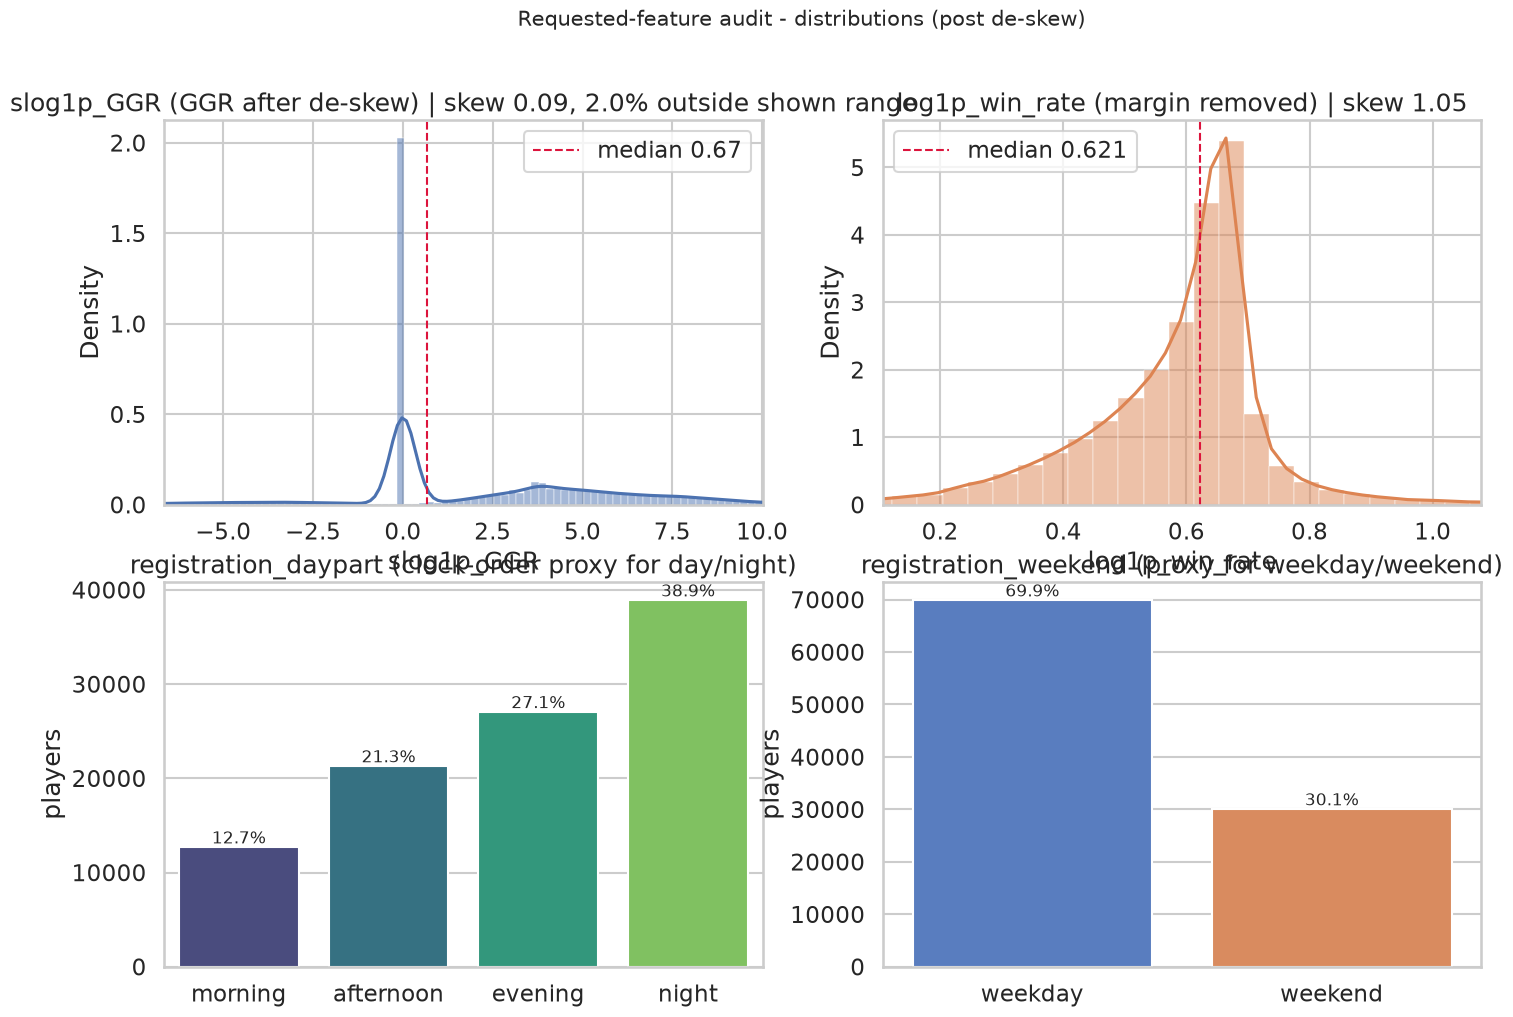

slog1p_GGR n=99,786  min -11.813  max 13.138
log1p_win_rate n=57,842  min 0.000  max 4.896


In [22]:
fig, axes = plt.subplots(2, 2, figsize=(17, 11))

# --- slog1p_GGR (transformed GGR): density --------------------------------
ax = axes[0, 0]
g = audit["slog1p_GGR"]
lo, hi = g.quantile(0.01), g.quantile(0.99)
sns.histplot(g.dropna(), bins=120, kde=True, stat="density", ax=ax)
ax.axvline(g.median(), ls="--", c="crimson", lw=1.5, label=f"median {g.median():.2f}")
outside = ((g < lo) | (g > hi)).mean() * 100
ax.set_xlim(lo, hi)
ax.set_title(f"slog1p_GGR (GGR after de-skew) | skew {g.skew():.2f}, "
             f"{outside:.1f}% outside shown range")
ax.legend()

# --- log1p_win_rate (margin removed: == 1 - win_rate) ----------------------
ax = axes[0, 1]
w = audit["log1p_win_rate"]
wlo, whi = w.quantile(0.01), w.quantile(0.99)
sns.histplot(w.dropna(), bins=120, kde=True, stat="density", ax=ax,
             color=sns.color_palette()[1])
ax.axvline(w.median(), ls="--", c="crimson", lw=1.5, label=f"median {w.median():.3f}")
ax.set_xlim(wlo, whi)
ax.set_title(f"log1p_win_rate (margin removed) | skew {w.skew():.2f}")
ax.legend()

# --- registration_daypart: density (share) --------------------------------
ax = axes[1, 0]
order = ["morning", "afternoon", "evening", "night"]
counts = audit["registration_daypart"].value_counts().reindex(order)
shares = counts / counts.sum()
sns.barplot(x=order, y=counts.values, hue=order, palette="viridis",
            legend=False, ax=ax)
for i, (v, p) in enumerate(zip(counts.values, shares.values)):
    ax.text(i, v + counts.max() * 0.01, f"{p:.1%}", ha="center", fontsize=12)
ax.set_ylabel("players")
ax.set_title("registration_daypart (clock-order proxy for day/night)")

# --- registration_weekend: density (share) --------------------------------
ax = axes[1, 1]
labels = ["weekday", "weekend"]
cw = audit["registration_weekend"].value_counts().reindex([False, True])
sw = cw / cw.sum()
sns.barplot(x=labels, y=cw.values, hue=labels, palette="muted",
            legend=False, ax=ax)
for i, (v, p) in enumerate(zip(cw.values, sw.values)):
    ax.text(i, v + cw.max() * 0.01, f"{p:.1%}", ha="center", fontsize=12)
ax.set_ylabel("players")
ax.set_title("registration_weekend (proxy for weekday/weekend)")

fig.suptitle("Requested-feature audit - distributions (post de-skew)",
             fontsize=15)
plt.savefig(f"{OUT}/audit_distributions.png", dpi=120, bbox_inches="tight")
plt.show()

print(f"slog1p_GGR n={g.notna().sum():,}  min {g.min():.3f}  max {g.max():.3f}")
print(f"log1p_win_rate n={w.notna().sum():,}  min {w.min():.3f}  max {w.max():.3f}")

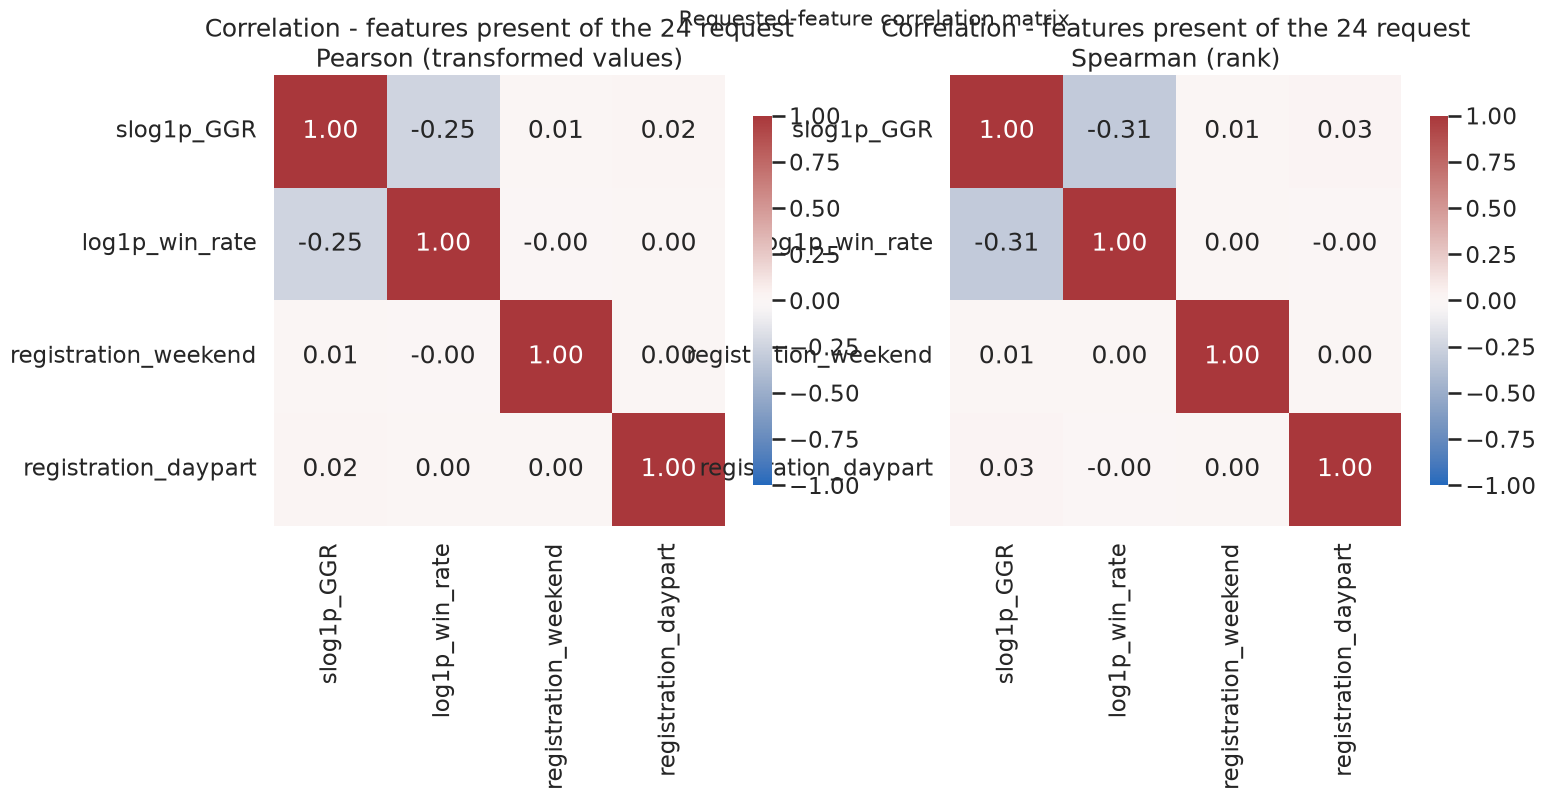

pearson                                      \
                     slog1p_GGR log1p_win_rate registration_weekend   
slog1p_GGR                1.000         -0.247                0.012   
log1p_win_rate           -0.247          1.000               -0.001   
registration_weekend      0.012         -0.001                1.000   
registration_daypart      0.022          0.004                0.002   

                                            spearman                 \
                     registration_daypart slog1p_GGR log1p_win_rate   
slog1p_GGR                          0.022      1.000         -0.312   
log1p_win_rate                      0.004     -0.312          1.000   
registration_weekend                0.002      0.014          0.001   
registration_daypart                1.000      0.027         -0.001   

                                                                
                     registration_weekend registration_daypart  
slog1p_GGR                          0.014                0.027  
log1p_win_rate                      0.001               -0.001  
registration_weekend                1.000                0.004  
registration_daypart                0.004                1.000

pairs |pearson| > 0.3:


In [23]:
DAYPART_ORD = {"morning": 0, "afternoon": 1, "evening": 2, "night": 3}
numf = pd.DataFrame({
    "slog1p_GGR": audit["slog1p_GGR"],
    "log1p_win_rate": audit["log1p_win_rate"],
    "registration_weekend": audit["registration_weekend"].astype(float),
    "registration_daypart": audit["registration_daypart"].map(DAYPART_ORD).astype(float),
})
pearson = numf.corr(method="pearson")
spearman = numf.rank().corr()          # == Spearman (scipy unavailable)
corr = pd.concat({"pearson": pearson, "spearman": spearman}, axis=1)
corr.to_csv(f"{OUT}/audit_correlations.csv")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (mat, name) in zip(axes, [(pearson, "Pearson (transformed values)"),
                                  (spearman, "Spearman (rank)")]):
    sns.heatmap(mat, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
                square=True, cbar_kws={"shrink": 0.8}, ax=ax)
    ax.set_title(f"Correlation - features present of the 24 request\n{name}")
fig.suptitle("Requested-feature correlation matrix", fontsize=15)
plt.savefig(f"{OUT}/audit_corr.png", dpi=120, bbox_inches="tight")
plt.show()

display(corr.round(3))
print("pairs |pearson| > 0.3:")
for a in numf.columns:
    for b in numf.columns:
        if a < b and abs(pearson.loc[a, b]) > 0.3:
            print(f"  {a} <-> {b}: r={pearson.loc[a, b]:.3f}  "
                  f"rho={spearman.loc[a, b]:.3f}")

## Full-feature correlation matrix — transformed dataset

Correlation over **all numeric features** of `transformed_data/player_dataset.csv`
(the de-skewed feature space built in requests 1–3: `log1p` / `slog1p` columns,
monetary_scale, derived rates, VIP/AML/account flags).

Scope: every int/float/bool column (binary flags included — their correlation is
point-biserial); `player_id` dropped (key), `vip_level` dropped because it is
**constant** (1.0 on its 1,057 non-null rows → undefined variance). Nominal ID
codes (`ad_campaign_id`, `ad_group_id`, `ad_keyword_id`, `referrer_player_id`) are
in the matrix but their linear correlation is meaningless — they are excluded from
the "meaningful top pairs" list.

Because the money/count features are now `log1p`-scaled, Pearson on them is
meaningful. Spearman (rank-based, via `rank().corr()`) is shown alongside for the
skewed leftovers, and a **redundancy report** (|Pearson| > 0.95) flags
near-duplicate columns ahead of clustering.

Outputs: `new_eda_output/full_correlations.csv` (Pearson + Spearman) and
`full_corr_pearson.png` (both matrices side-by-side, PC1-seriated order).

In [24]:
DS = "transformed_data/player_dataset.csv"
ID_COLS = ["ad_campaign_id", "ad_group_id", "ad_keyword_id", "referrer_player_id"]

cur = pd.read_csv(DS, low_memory=False)
num = [c for c in cur.columns if pd.api.types.is_numeric_dtype(cur[c])]
kept = [c for c in num
        if c not in ("player_id",) and cur[c].nunique(dropna=True) > 1]
dropped = [c for c in num if c not in kept]
print(f"numeric columns: {len(num)} | kept {len(kept)} | dropped {dropped}")
flag_cols = [c for c in kept if cur[c].dtype == bool]
print(f"binary flags in matrix: {flag_cols}")

curm = cur[kept].apply(pd.to_numeric, errors="raise")
pearson = curm.corr(method="pearson")
spearman = curm.rank().corr()
full_corr = pd.concat({"pearson": pearson, "spearman": spearman}, axis=1)
full_corr.to_csv(f"{OUT}/full_correlations.csv")
print(f"[saved] {OUT}/full_correlations.csv  ({len(kept)}x{len(kept)} x 2 methods)")

# --- redundancy report (|Pearson| > 0.95) ----------------------------------
pairs = []
for a in pearson.columns:
    for b in pearson.columns:
        if a < b:
            pairs.append({"a": a, "b": b,
                          "pearson": pearson.loc[a, b], "spearman": spearman.loc[a, b]})
tp = pd.DataFrame(pairs)
tp["abs"] = tp["pearson"].abs()
red = tp[tp["abs"] > 0.95].sort_values("abs", ascending=False)
print("\nredundant pairs |pearson| > 0.95 (%d):" % len(red))
display(red.reset_index(drop=True))

# --- meaningful top pairs (id codes excluded) ------------------------------
m = tp[~tp["a"].isin(ID_COLS) & ~tp["b"].isin(ID_COLS)].sort_values("abs",
                                                                     ascending=False)
print("\ntop 20 meaningful pairs (no id codes):")
display(m.head(20).reset_index(drop=True))

numeric columns: 36 | kept 34 | dropped ['player_id', 'vip_level']
binary flags in matrix: ['is_closed', 'is_active', 'registration_weekend', 'referral_flag', 'is_pep', 'has_sanctions']


[saved] new_eda_output/full_correlations.csv  (34x34 x 2 methods)

redundant pairs |pearson| > 0.95 (20):


,a,b,pearson,spearman,abs
0,log1p_login_frequency,log1p_login_rate,1.000000,1.000000,1.000000
1,log1p_betting_intensity,log1p_betting_to_deposit_ratio,1.000000,1.000000,1.000000
2,log1p_bets_per_month,log1p_betting_rate,1.000000,1.000000,1.000000
3,log1p_deposit_rate,log1p_deposits_per_month,1.000000,1.000000,1.000000
4,ad_campaign_id,ad_keyword_id,1.000000,0.273371,1.000000
5,ad_group_id,ad_keyword_id,0.999982,0.485604,0.999982
6,ad_campaign_id,ad_group_id,0.999979,0.647793,0.999979
7,log1p_betting_rate,log1p_winning_rate,0.996442,0.997608,0.996442
8,log1p_bets_per_month,log1p_winning_rate,0.996442,0.997608,0.996442
9,log1p_total_wins,log1p_winning_rate,0.967719,0.983807,0.967719



top 20 meaningful pairs (no id codes):


,a,b,pearson,spearman,abs
0,log1p_betting_intensity,log1p_betting_to_deposit_ratio,1.000000,1.000000,1.000000
1,log1p_deposit_rate,log1p_deposits_per_month,1.000000,1.000000,1.000000
2,log1p_bets_per_month,log1p_betting_rate,1.000000,1.000000,1.000000
3,log1p_login_frequency,log1p_login_rate,1.000000,1.000000,1.000000
4,log1p_bets_per_month,log1p_winning_rate,0.996442,0.997608,0.996442
5,log1p_betting_rate,log1p_winning_rate,0.996442,0.997608,0.996442
6,log1p_total_wins,log1p_winning_rate,0.967719,0.983807,0.967719
7,log1p_bets_per_month,log1p_total_wins,0.966905,0.979228,0.966905
8,log1p_betting_rate,log1p_total_wins,0.966905,0.979228,0.966905
9,log1p_total_withdrawals,log1p_withdrawal_rate,0.966219,0.988444,0.966219


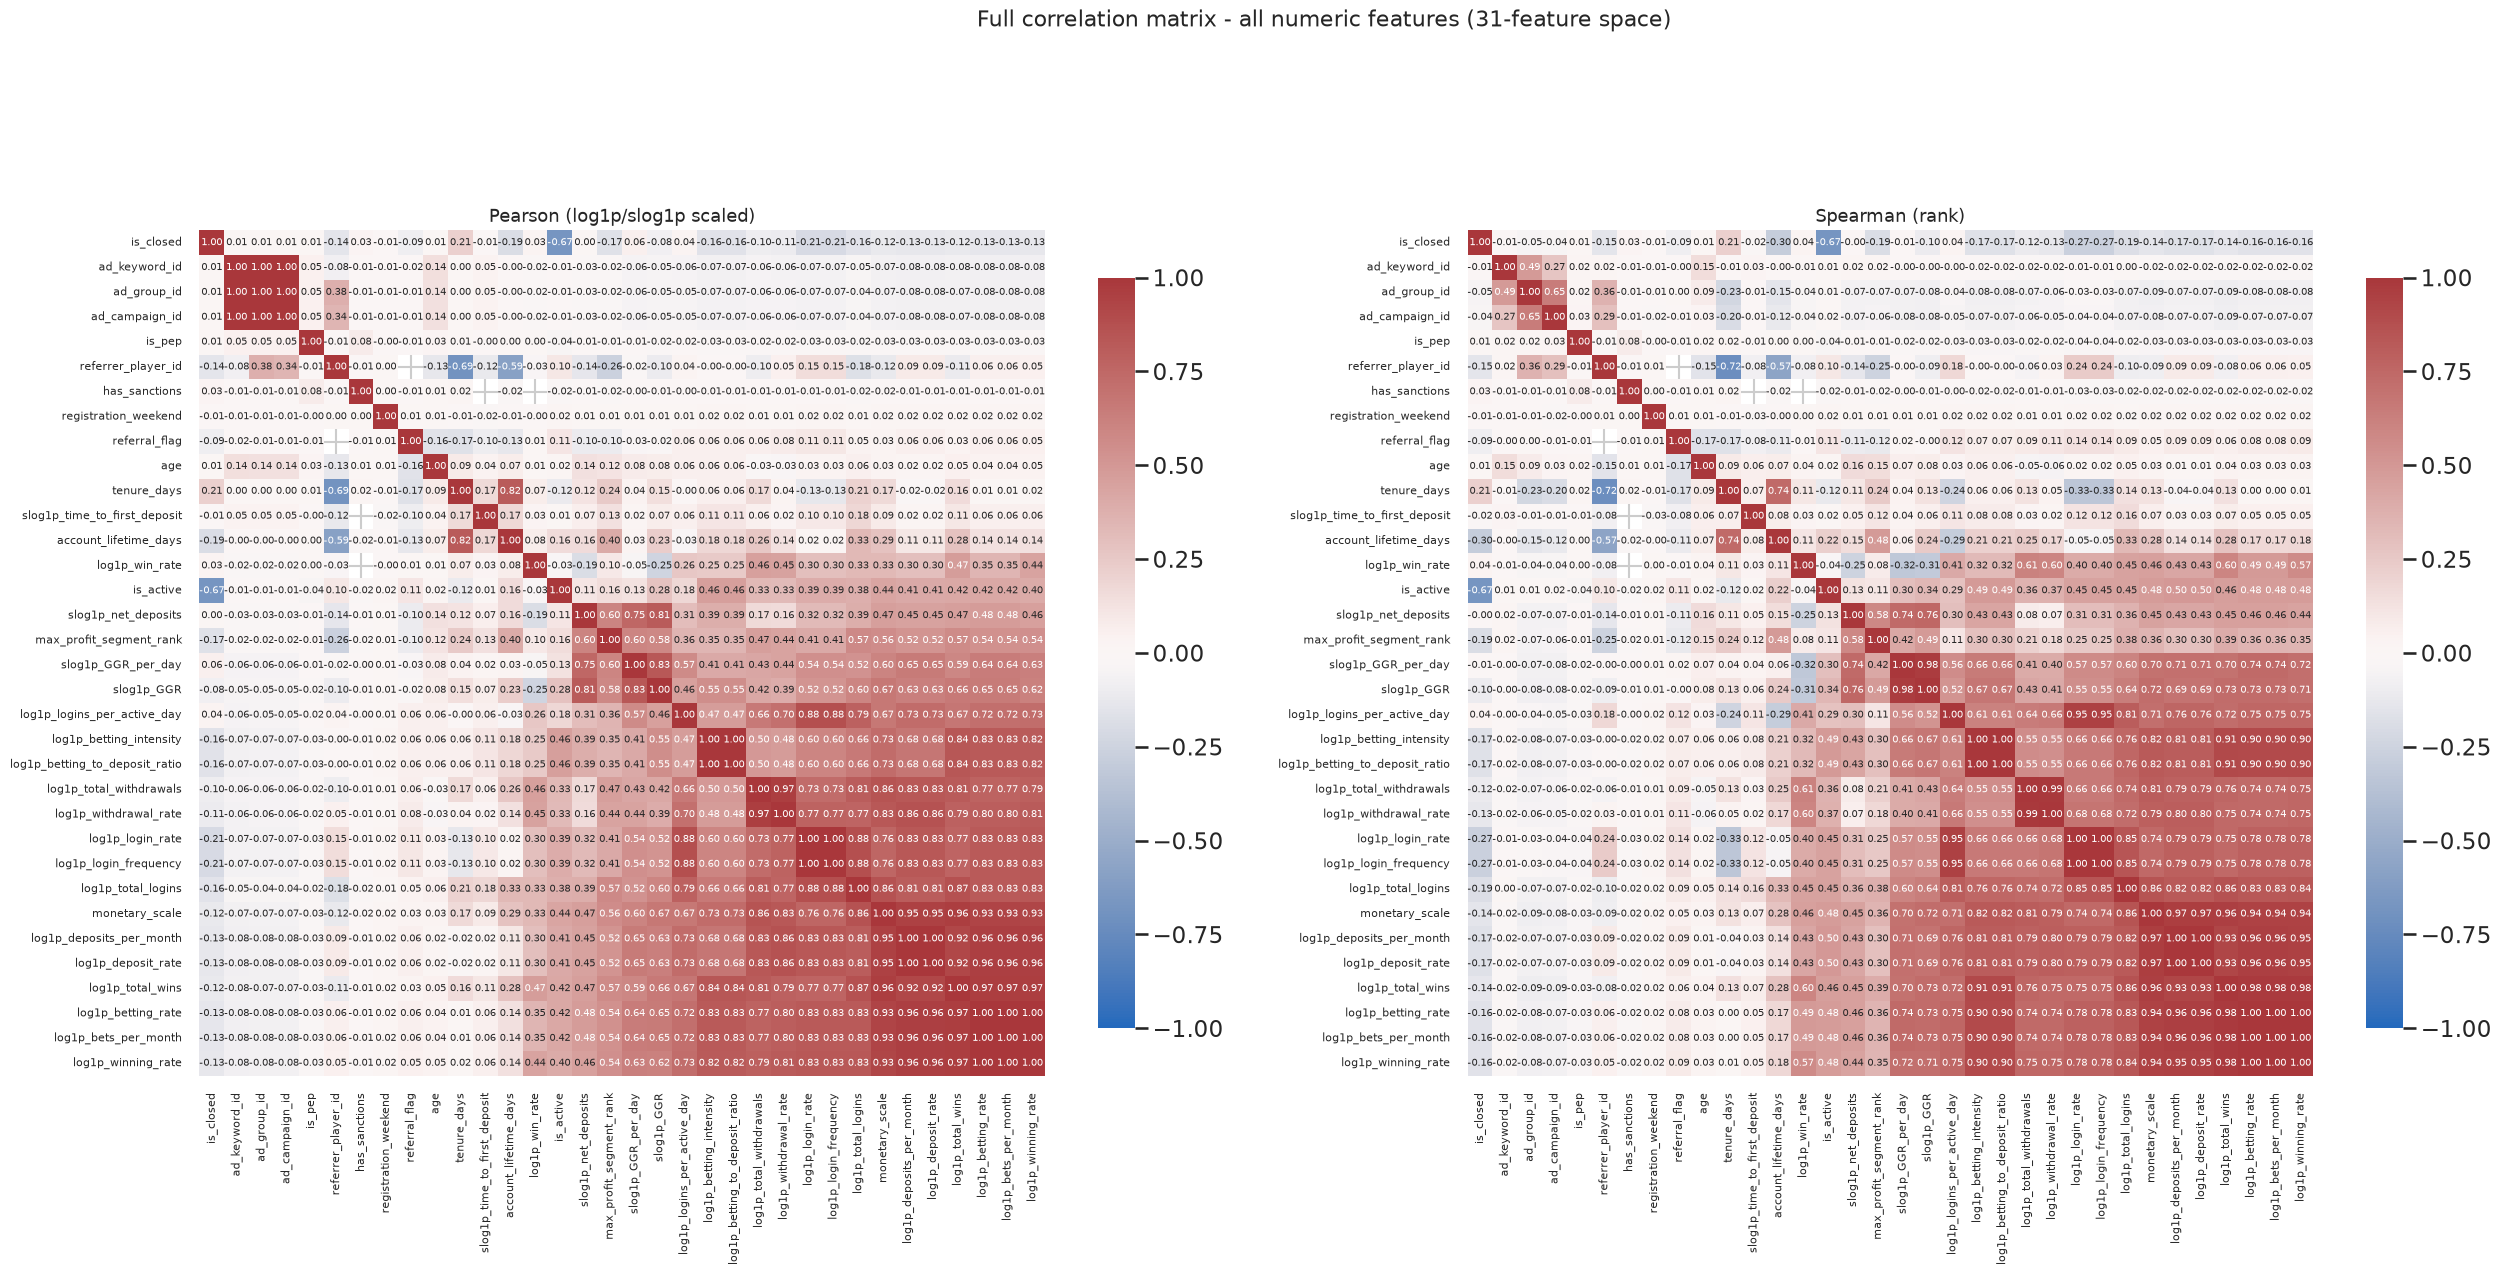

[saved] new_eda_output/full_corr_pearson.png (both Pearson+Spearman panels)


In [25]:
def seriate(corr):
    w, v = np.linalg.eigh(corr.to_numpy(dtype=float))
    return corr.index[np.argsort(v[:, int(np.argmax(np.abs(w)))])]

order = seriate(pearson.fillna(0.0))
P = pearson.loc[order, order]
S = spearman.loc[order, order]

fig, axes = plt.subplots(1, 2, figsize=(30, 13))
for ax, (mat, name) in zip(axes, [(P, "Pearson (log1p/slog1p scaled)"),
                                  (S, "Spearman (rank)")]):
    sns.heatmap(mat, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
                square=True, cbar_kws={"shrink": 0.75}, ax=ax,
                annot_kws={"size": 7})
    ax.tick_params(axis="x", rotation=90, labelsize=8)
    ax.tick_params(axis="y", rotation=0, labelsize=8)
    ax.set_title(name, fontsize=13)
fig.suptitle("Full correlation matrix - all numeric features (31-feature space)",
             fontsize=16, y=0.99)
plt.savefig(f"{OUT}/full_corr_pearson.png", dpi=120, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"[saved] {OUT}/full_corr_pearson.png (both Pearson+Spearman panels)")


## Requested 11-feature matrix — log form where skew > 3

Feature set (LIFECYCLE / ENGAGEMENT / ECONOMIC / OPTIONAL) built from
`features/player_features.csv` raw+derived columns (`bets_to_deposit_ratio` is
`turnover_to_deposit_ratio` = total_bets / total_deposits; `has_deposited` is
derived from `first_deposit_day`):

| requested | form used |
|---|---|
| `tenure_days` | raw (skew 0.9 < 3) |
| `time_to_first_deposit` | `slog1p` (skew 8.7; has negatives) |
| `has_deposited` | raw binary flag |
| `log1p(total_logins)` | `log1p` (as requested) |
| `login_rate` | `log1p` (skew 3.6 > 3) |
| `log1p(total_deposits)` | `log1p` (as requested) |
| `log1p(total_withdrawals)` | `log1p` (as requested) |
| `turnover_to_deposit_ratio` | `log1p` (skew >> 3) |
| `withdrawal_ratio` | `log1p` (skew > 3) |
| `bets_per_login` | `log1p` (skew > 3) |
| `net_deposits` | `slog1p` = sign(x)*log1p(|x|) (skew 23.6; has negatives) |

Rule: |skew| > 3 → non-negative uses `log1p`, negative-carrying uses `slog1p`;
the three explicit `log1p()` requests are honoured. Pearson + Spearman (rank),
PC1-seriated annotated heatmap.

Outputs: `new_eda_output/requested_11_correlations.csv`,
`new_eda_output/requested_11_corr.png`

In [26]:
SRC = "Data Science Task Data.xlsx - Result 1.csv"
FEATS = "features/player_features.csv"

raw = pd.read_csv(SRC, low_memory=False, parse_dates=["first_deposit_day"],
                  usecols=["player_id", "first_deposit_day"])
pf1 = pd.read_csv(FEATS, low_memory=False, usecols=[
    "player_id", "tenure_days", "time_to_first_deposit", "total_logins",
    "login_rate", "total_deposits", "total_withdrawals", "withdrawal_ratio",
    "bets_per_login", "net_deposits", "bets_to_deposit_ratio"])
pf1 = pf1.merge(raw, on="player_id", how="left")
pf1["has_deposited"] = pf1["first_deposit_day"].notna()
pf1 = pf1.rename(columns={"bets_to_deposit_ratio": "turnover_to_deposit_ratio"})

LOG_FORM = ["total_logins", "total_deposits", "total_withdrawals"]
FEATURES = ["tenure_days", "time_to_first_deposit", "has_deposited",
            "total_logins", "login_rate", "total_deposits",
            "total_withdrawals", "turnover_to_deposit_ratio",
            "withdrawal_ratio", "bets_per_login", "net_deposits"]


def _slog1p(x):
    return np.sign(x) * np.log1p(np.abs(x))


OUT_C = {}
FORM_TABLE = []
for c in FEATURES:
    s = pf1[c].dropna()
    sk = s.skew()
    use_log = c in LOG_FORM or (abs(sk) > 3 and c != "has_deposited")
    if use_log:
        name = f"log1p_{c}" if s.min() >= 0 else f"slog1p_{c}"
        sx = np.log1p(s) if s.min() >= 0 else _slog1p(s)
        OUT_C[name] = sx
        FORM_TABLE.append({"requested": c, "form": name, "skew_raw": round(sk, 1),
                           "skew_after": round(sx.skew(), 2)})
    else:
        OUT_C[c] = s
        FORM_TABLE.append({"requested": c, "form": c, "skew_raw": round(sk, 1),
                           "skew_after": round(sk, 2)})

form_tbl = pd.DataFrame(FORM_TABLE)
print("forms applied:")
display(form_tbl)

mat = pd.DataFrame(OUT_C)
print(f"\nmatrix frame: {mat.shape}  n-rows available: {mat.notna().sum().to_dict()}")

forms applied:


,requested,form,skew_raw,skew_after
0,tenure_days,tenure_days,0.9,0.86
1,time_to_first_deposit,slog1p_time_to_first_deposit,8.7,2.79
2,has_deposited,has_deposited,-0.4,-0.41
3,total_logins,log1p_total_logins,7.6,1.05
4,login_rate,log1p_login_rate,3.6,0.98
5,total_deposits,log1p_total_deposits,24.1,0.60
6,total_withdrawals,log1p_total_withdrawals,26.6,0.97
7,turnover_to_deposit_ratio,log1p_turnover_to_deposit_ratio,49.5,0.25
8,withdrawal_ratio,log1p_withdrawal_ratio,25.3,0.97
9,bets_per_login,log1p_bets_per_login,45.5,0.52



matrix frame: (100000, 11)  n-rows available: {'tenure_days': 100000, 'slog1p_time_to_first_deposit': 60067, 'has_deposited': 100000, 'log1p_total_logins': 99786, 'log1p_login_rate': 99494, 'log1p_total_deposits': 99786, 'log1p_total_withdrawals': 99786, 'log1p_turnover_to_deposit_ratio': 60068, 'log1p_withdrawal_ratio': 60068, 'log1p_bets_per_login': 97513, 'slog1p_net_deposits': 99786}


[saved] new_eda_output/requested_11_correlations.csv


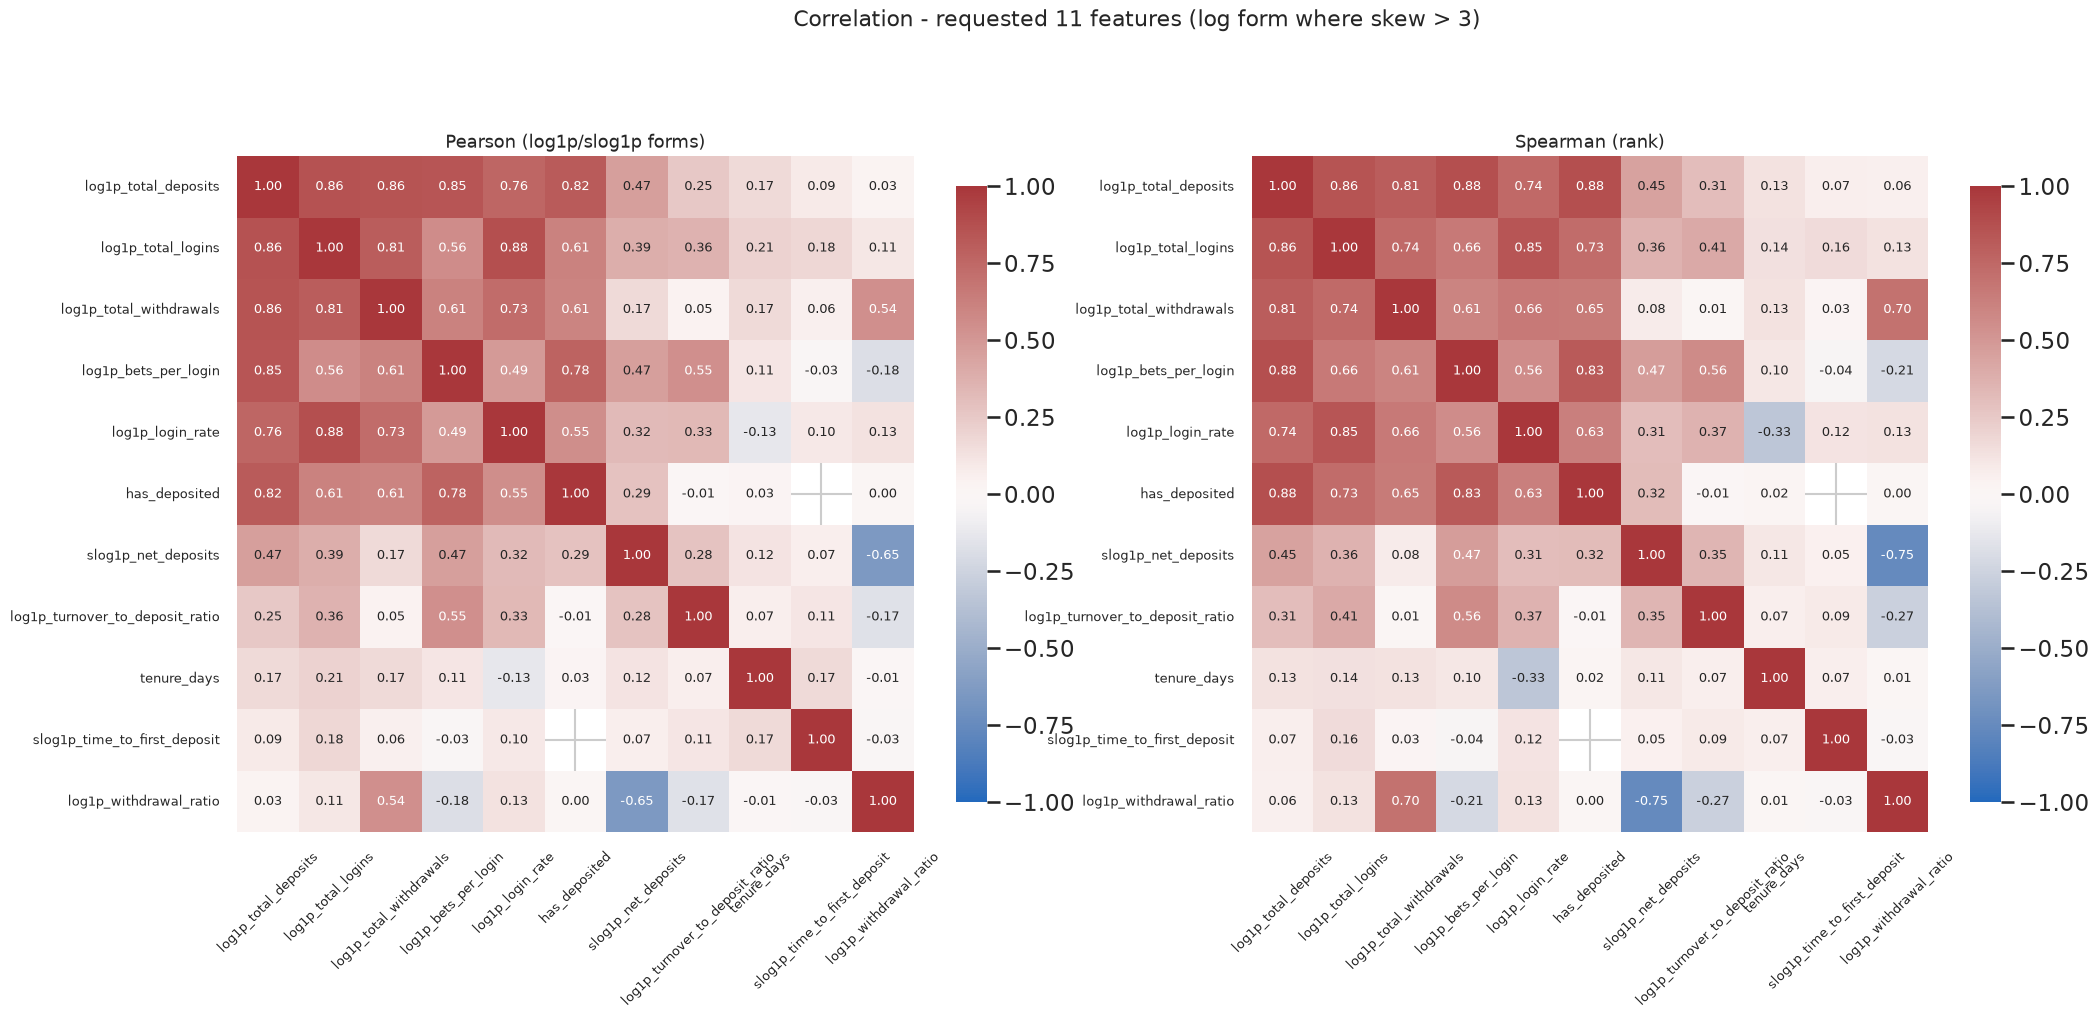

[saved] new_eda_output/requested_11_corr.png

top 10 pairs:


,a,b,pearson,spearman
0,log1p_login_rate,log1p_total_logins,0.883,0.846
1,log1p_total_deposits,log1p_total_logins,0.862,0.856
2,log1p_total_deposits,log1p_total_withdrawals,0.857,0.807
3,log1p_bets_per_login,log1p_total_deposits,0.849,0.878
4,has_deposited,log1p_total_deposits,0.816,0.877
5,log1p_total_logins,log1p_total_withdrawals,0.811,0.742
6,has_deposited,log1p_bets_per_login,0.778,0.826
7,log1p_login_rate,log1p_total_deposits,0.760,0.745
8,log1p_login_rate,log1p_total_withdrawals,0.728,0.662
9,log1p_withdrawal_ratio,slog1p_net_deposits,-0.646,-0.751


In [27]:
P11 = mat.corr(method="pearson")
S11 = mat.rank().corr()
corr11 = pd.concat({"pearson": P11, "spearman": S11}, axis=1)
corr11.to_csv(f"{OUT}/requested_11_correlations.csv")
print(f"[saved] {OUT}/requested_11_correlations.csv")

order = seriate(P11.fillna(0.0))
fig, axes = plt.subplots(1, 2, figsize=(24, 10))
for ax, (mat2, name) in zip(axes, [(P11, "Pearson (log1p/slog1p forms)"),
                                   (S11, "Spearman (rank)")]):
    sns.heatmap(mat2.loc[order, order], annot=True, fmt=".2f", cmap="vlag",
                vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.8}, ax=ax,
                annot_kws={"size": 9})
    ax.tick_params(axis="x", rotation=45, labelsize=9)
    ax.tick_params(axis="y", rotation=0, labelsize=9)
    ax.set_title(name, fontsize=13)
fig.suptitle("Correlation - requested 11 features (log form where skew > 3)",
             fontsize=16, y=0.98)
plt.savefig(f"{OUT}/requested_11_corr.png", dpi=120, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"[saved] {OUT}/requested_11_corr.png")

pairs = []
for a in P11.columns:
    for b in P11.columns:
        if a < b:
            pairs.append({"a": a, "b": b,
                          "pearson": round(P11.loc[a, b], 3),
                          "spearman": round(S11.loc[a, b], 3)})
tp = pd.DataFrame(pairs).sort_values("pearson", key=lambda x: x.abs(),
                                     ascending=False)
print("\ntop 10 pairs:")
display(tp.head(10).reset_index(drop=True))